# NYC Taxi Fares — EDA, Preprocessing Pipeline and Baseline Models (v2)

This notebook predicts `fare_amount` for 500,000 NYC taxi trips (2009–2015). It is a rebuild of `Task-2.ipynb` with four changes:

1. **A tighter EDA** — one audit table instead of a cell per check, plots on cleaned data, and effect sizes behind every "no influence" answer. The eight task questions (Q1–Q8) are kept.
2. **Preprocessing inside a scikit-learn `Pipeline`** — the train/test split happens *before* anything is fitted, so no step ever sees test rows.
3. **Baselines** — seven models from "always predict the median" to gradient boosting, compared with the same cross-validation.
4. **An honest evaluation** — the original notebook used `fare_per_km = fare_amount / distance` as a feature, which hands the model the answer. Section 10 measures how much that inflated its scores.

| Section | Content |
|---|---|
| 0–1 | Setup, loading, standardising units |
| 2–3 | Data-quality audit and cleaning |
| 4 | Exploratory analysis and Q1–Q8 |
| 5–6 | Train/test split, feature engineering, preprocessing pipeline |
| 7–8 | Baseline models and tuning |
| 9–10 | Test-set evaluation and the leakage check |
| 11 | Saving and reusing the pipeline |
| 12 | Task 3: model comparison, selection and the files for the Flask app |

## 0. Setup

In [1]:
%pip install -q gdown
import importlib
import json
import os
import time

import gdown
import joblib
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from scipy.stats import binned_statistic_2d
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, median_absolute_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_validate, learning_curve, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

Note: you may need to restart the kernel to use updated packages.


In [2]:
RANDOM_STATE = 42
TARGET = 'fare_amount'

COORD_COLS = ['pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude']
CAT_COLS = ['Car Condition', 'Weather', 'Traffic Condition']
ID_COLS = ['User ID', 'User Name', 'Driver Name', 'key']
DAYS = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']

MIN_FARE = 2.50
NYC_BOX = (40.40, 41.10, -74.40, -73.50)
MAP_BOX = (40.55, 40.92, -74.20, -73.70)
FARE_CHANGE = pd.Timestamp('2012-09-04')

PLOT_SAMPLE = 50_000
MI_SAMPLE = 20_000
TUNING_SAMPLE = 120_000
CURVE_SAMPLE = 150_000
IMPORTANCE_SAMPLE = 20_000

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
SURFACE, INK, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#898781', '#e1e0d9'
SEQ = mcolors.LinearSegmentedColormap.from_list('seq_blue', ['#eef5fd', '#cde2fb', '#86b6ef', '#3987e5', '#1c5cab', '#0d366b'])
SEQ_WARM = mcolors.LinearSegmentedColormap.from_list('seq_orange', ['#fdeee6', '#f6b79b', '#eb6834', '#a8431a', '#5e230b'])
DIVERGING = mcolors.LinearSegmentedColormap.from_list('blue_red', ['#104281', '#3987e5', '#f0efec', '#e34948', '#8f1f1f'])

sns.set_theme(style='whitegrid', palette=[BLUE, ORANGE, AQUA], rc={
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': '#c3c2b7',
    'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.titleweight': 'bold', 'axes.titlesize': 12,
    'axes.labelcolor': '#52514e', 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110,
})


def in_box(lat, lon, box):
    lat_min, lat_max, lon_min, lon_max = box
    return lat.between(lat_min, lat_max) & lon.between(lon_min, lon_max)

### Feature code as a module

The functions that turn a raw trip into model features are written to a small file, `trip_features.py`, and imported from there. The EDA and the model then share exactly one definition of "distance" and "airport", and the saved pipeline (section 11) can be loaded in another notebook or script: joblib stores a *reference* to these functions, so they have to live in an importable file rather than in a notebook cell.

In [3]:
%%writefile trip_features.py
import numpy as np
import pandas as pd

EARTH_RADIUS_KM = 6371.0
AIRPORT_RADIUS_KM = 2.0
MAX_FARE = 500.0
AIRPORTS = {'JFK': (40.6413, -73.7781), 'LGA': (40.7769, -73.8740), 'EWR': (40.6895, -74.1745)}

RAW_FEATURES = ['pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
                'passenger_count', 'Car Condition', 'Weather', 'Traffic Condition']
CAT_FEATURES = ['Car Condition', 'Weather', 'Traffic Condition']
NUM_FEATURES = ['trip_km', 'log_trip_km', 'manhattan_km', 'bearing_sin', 'bearing_cos',
                'pickup_lat', 'pickup_lon', 'dropoff_lat', 'dropoff_lon',
                'pickup_jfk_km', 'dropoff_jfk_km', 'pickup_lga_km', 'dropoff_lga_km', 'pickup_ewr_km', 'dropoff_ewr_km',
                'airport_pickup', 'airport_dropoff',
                'hour', 'hour_sin', 'hour_cos', 'weekday', 'is_weekend', 'is_night', 'is_rush_hour',
                'month', 'year', 'time_index', 'passenger_count']


def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km. All inputs in radians."""
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return EARTH_RADIUS_KM * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


def add_trip_features(X):
    """Raw trip columns (coordinates in radians) -> model features. Stateless: nothing is learned from the data."""
    plat, plon = X['pickup_latitude'].astype(float), X['pickup_longitude'].astype(float)
    dlat, dlon = X['dropoff_latitude'].astype(float), X['dropoff_longitude'].astype(float)
    out = pd.DataFrame(index=X.index)

    trip_km = haversine_km(plat, plon, dlat, dlon)
    out['trip_km'] = trip_km
    out['log_trip_km'] = np.log1p(trip_km)
    out['manhattan_km'] = haversine_km(plat, plon, dlat, plon) + haversine_km(dlat, plon, dlat, dlon)
    bearing = np.arctan2(np.sin(dlon - plon) * np.cos(dlat),
                         np.cos(plat) * np.sin(dlat) - np.sin(plat) * np.cos(dlat) * np.cos(dlon - plon))
    out['bearing_sin'] = np.sin(bearing)
    out['bearing_cos'] = np.cos(bearing)

    out['pickup_lat'], out['pickup_lon'] = np.degrees(plat), np.degrees(plon)
    out['dropoff_lat'], out['dropoff_lon'] = np.degrees(dlat), np.degrees(dlon)

    for name, (lat, lon) in AIRPORTS.items():
        lat, lon = np.radians(lat), np.radians(lon)
        out[f'pickup_{name.lower()}_km'] = haversine_km(plat, plon, lat, lon)
        out[f'dropoff_{name.lower()}_km'] = haversine_km(dlat, dlon, lat, lon)
    pickup_cols = [f'pickup_{name.lower()}_km' for name in AIRPORTS]
    dropoff_cols = [f'dropoff_{name.lower()}_km' for name in AIRPORTS]
    out['airport_pickup'] = (out[pickup_cols].min(axis=1) <= AIRPORT_RADIUS_KM).astype(int)
    out['airport_dropoff'] = (out[dropoff_cols].min(axis=1) <= AIRPORT_RADIUS_KM).astype(int)

    dt = pd.to_datetime(X['pickup_datetime'], utc=True, errors='coerce')
    hour = dt.dt.hour + dt.dt.minute / 60
    out['hour'] = hour
    out['hour_sin'] = np.sin(2 * np.pi * hour / 24)
    out['hour_cos'] = np.cos(2 * np.pi * hour / 24)
    out['weekday'] = dt.dt.weekday
    out['is_weekend'] = (dt.dt.weekday >= 5).astype(int)
    out['is_night'] = ((hour >= 20) | (hour < 6)).astype(int)
    out['is_rush_hour'] = ((dt.dt.weekday < 5) & (hour >= 16) & (hour < 20)).astype(int)
    out['month'] = dt.dt.month
    out['year'] = dt.dt.year
    out['time_index'] = dt.dt.year + (dt.dt.dayofyear - 1) / 365.25
    out['passenger_count'] = X['passenger_count'].astype(float)

    for col in CAT_FEATURES:
        if col in X.columns:
            out[col] = X[col]
    return out


def log_fare(y):
    return np.log1p(y)


def exp_fare(z):
    """Inverse of log_fare, capped at the largest fare in the data so one extreme trip cannot explode."""
    return np.expm1(np.clip(z, None, np.log1p(MAX_FARE)))

Overwriting trip_features.py


In [4]:
import trip_features
importlib.reload(trip_features)
from trip_features import (AIRPORTS, AIRPORT_RADIUS_KM, CAT_FEATURES, NUM_FEATURES, RAW_FEATURES,
                           add_trip_features, exp_fare, haversine_km, log_fare)

## 1. Load and standardise

Two things are fixed once here so that no later cell has to remember them:

* `pickup_datetime` is parsed to a real timestamp.
* The coordinates are stored in **radians**. Degree versions (`pickup_lat`, `pickup_lon`, `dropoff_lat`, `dropoff_lon`) are added for maps and bounding-box checks. The check below confirms the assumption: the median pickup must land in New York.

In [5]:
URL = "https://drive.google.com/file/d/13SXMNuaNrJznox9WanKkgPjRObSX6I8M/view"
if not os.path.exists("data.csv"):
    gdown.download(URL, "data.csv", fuzzy=True, quiet=True)
raw = pd.read_csv("data.csv")
print(f"Loaded {raw.shape[0]:,} rows x {raw.shape[1]} columns")

Loaded 500,000 rows x 26 columns


In [6]:
df = raw.copy()
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'], utc=True, errors='coerce').dt.tz_localize(None)
df['pickup_lat'], df['pickup_lon'] = np.degrees(df['pickup_latitude']), np.degrees(df['pickup_longitude'])
df['dropoff_lat'], df['dropoff_lon'] = np.degrees(df['dropoff_latitude']), np.degrees(df['dropoff_longitude'])

print(f"Unparsed timestamps: {df['pickup_datetime'].isna().sum():,}")
print(f"Date range: {df['pickup_datetime'].min()} to {df['pickup_datetime'].max()}")
print(f"Median pickup: {df['pickup_lat'].median():.4f} deg N, {df['pickup_lon'].median():.4f} deg E")
assert in_box(pd.Series([df['pickup_lat'].median()]), pd.Series([df['pickup_lon'].median()]), NYC_BOX).all(), \
    "Median pickup is not in New York - the radians assumption is wrong"

Unparsed timestamps: 0
Date range: 2009-01-01 00:31:32 to 2015-06-30 23:38:21
Median pickup: 40.7527 deg N, -73.9818 deg E


## 2. Data-quality audit

### 2.1 Column overview

One row per column: type, missing values, number of distinct values and (for numeric columns) the range. Things to look for: impossible minimums and maximums, columns that are identifiers (as many distinct values as rows), and columns with missing values.

In [7]:
overview = pd.DataFrame({
    'dtype': raw.dtypes.astype(str),
    'missing': raw.isna().sum(),
    'unique': raw.nunique(),
}).join(raw.describe().T[['min', '50%', 'max']].rename(columns={'50%': 'median'}))
display(overview)

print(f"Fully duplicated rows:   {raw.duplicated().sum():,}")
print(f"Duplicated `key` values: {raw['key'].duplicated().sum():,}")
print(f"Constant columns:        {[c for c in raw.columns if raw[c].nunique() == 1] or 'none'}")
for col in ['User ID', 'Driver Name']:
    counts = raw[col].value_counts()
    print(f"{col}: {len(counts):,} distinct, busiest appears {counts.iloc[0]:,} times")

,dtype,missing,unique,min,median,max
User ID,object,0,500000,NaN,NaN,NaN
User Name,object,0,221675,NaN,NaN,NaN
Driver Name,object,0,221700,NaN,NaN,NaN
Car Condition,object,0,4,NaN,NaN,NaN
Weather,object,0,5,NaN,NaN,NaN
Traffic Condition,object,0,3,NaN,NaN,NaN
key,object,0,500000,NaN,NaN,NaN
fare_amount,float64,0,1688,-44.900000,8.500000,500.000000
pickup_datetime,object,0,461206,NaN,NaN,NaN
pickup_longitude,float64,0,95037,-52.119764,-1.291226,37.360538


Fully duplicated rows:   0
Duplicated `key` values: 0


Constant columns:        none
User ID: 500,000 distinct, busiest appears 1 times
Driver Name: 221,700 distinct, busiest appears 257 times


**Result.** `User ID` has 500,000 distinct values in 500,000 rows: no customer appears twice, so there are no repeat customers to learn from. `Driver Name` has 221,700 distinct values and the busiest one appears 257 times, but `User Name` has almost the same number of distinct values (221,675), which suggests both columns come from the same pool of generated names rather than from tracked people. All four identifier columns are dropped before modelling.

The range columns already show the problems that section 2.3 turns into rules: a minimum fare of −\$44.90, coordinates of −59 and +37 radians, a maximum `distance` of 12,400 km, passenger counts of 0, and 5 rows with no dropoff.

### 2.2 Can the provided engineered columns be trusted?

The file ships with columns somebody else computed: `distance`, `bearing`, the calendar fields and five `*_dist` landmark distances. Before using them, each is recomputed from the raw coordinates and timestamp and compared.

In [8]:
sane = in_box(df['pickup_lat'], df['pickup_lon'], NYC_BOX) & in_box(df['dropoff_lat'], df['dropoff_lon'], NYC_BOX)

own_km = haversine_km(df['pickup_latitude'], df['pickup_longitude'], df['dropoff_latitude'], df['dropoff_longitude'])
moving = sane & (own_km > 0.1)
ratio = df.loc[moving, 'distance'] / own_km[moving]
print("`distance` vs. our haversine distance in km")
print(f"  median ratio: {ratio.median():.4f}   rows within 1%: {(np.abs(ratio - 1) <= 0.01).mean():.1%}\n")

print("Calendar columns vs. the parsed timestamp (share of rows that agree)")
for col, values in [('hour', df['pickup_datetime'].dt.hour), ('day', df['pickup_datetime'].dt.day),
                    ('month', df['pickup_datetime'].dt.month), ('weekday', df['pickup_datetime'].dt.weekday),
                    ('year', df['pickup_datetime'].dt.year)]:
    print(f"  {col:<8} {(df[col] == values).mean():.1%}")

rows = []
for name, (lat, lon) in AIRPORTS.items():
    lat, lon = np.radians(lat), np.radians(lon)
    from_pickup = haversine_km(df['pickup_latitude'], df['pickup_longitude'], lat, lon)[sane]
    from_dropoff = haversine_km(df['dropoff_latitude'], df['dropoff_longitude'], lat, lon)[sane]
    given = df.loc[sane, f'{name.lower()}_dist']
    for label, ours in [('pickup only', from_pickup), ('dropoff only', from_dropoff), ('pickup + dropoff', from_pickup + from_dropoff)]:
        rows.append({'column': f'{name.lower()}_dist', 'if it means': label,
                     'median ratio (given / ours)': (given / ours).median(),
                     'rows within 1%': (np.abs(given - ours) <= 0.01 * ours).mean()})
landmark_check = pd.DataFrame(rows).set_index(['column', 'if it means'])
display(landmark_check.style.format({'median ratio (given / ours)': '{:.3f}', 'rows within 1%': '{:.1%}'}))

`distance` vs. our haversine distance in km
  median ratio: 1.0000   rows within 1%: 100.0%

Calendar columns vs. the parsed timestamp (share of rows that agree)
  hour     100.0%
  day      100.0%
  month    100.0%
  weekday  100.0%
  year     100.0%


**Result.**

* **`distance` is the straight-line (haversine) distance in km.** The median ratio to our own calculation is 1.0000 and 100.0% of rows are within 1%.
* **The calendar columns were derived from this timestamp**, with Monday = 0: all five agree on 100.0% of rows. This check cannot say whether the timestamp is New York local time, because both sides come from the same value. The evidence for local time is the demand profile in Q6: the quietest hour is 5:00 and the busiest 19:00, which is the pattern of a city's local clock. If the timestamps were UTC, both would sit four to five hours later.
* **`jfk_dist` is the pickup distance plus the dropoff distance to JFK**, not the pickup distance alone: the sum has a ratio of 1.002 with 99.2% of rows within 1%, while pickup-only and dropoff-only are off by a factor of 2.0 with 0% of rows matching. The original notebook read this column as "distance from pickup to JFK", which is about half its real value.
* **`lga_dist` and `ewr_dist` are not fully identified.** The sum is again the closest reading (ratios 1.012 and 0.967), but only 13.7% and 0.1% of rows are within 1%, so they were computed from reference points that differ from the airport coordinates used here.

The model does not depend on any of these columns: section 6 recomputes pickup and dropoff distances to each airport separately, which carries at least as much information and has a known definition.

### 2.3 Validity rules

A row is invalid if it breaks a rule that follows from what a NYC taxi trip *is* — not from a statistical cut-off:

| Rule | Reason |
|---|---|
| missing value | 5 rows have no dropoff |
| fare below \$2.50 | \$2.50 was the initial charge throughout 2009–2015, so nothing can cost less |
| passenger count not 1–6 | 0 passengers is not a trip |
| pickup / dropoff outside the NYC area | a box of roughly 80 × 75 km around the city; this catches (0, 0) GPS defaults and corrupted coordinates in one rule, replacing the original "zero coordinate" and "distance > 200 km" rules |
| distance = 0 | pickup and dropoff are the same point, usually a GPS failure |
| fare above \$100 for under 1 km | the one rule that looks at the target; kept from the original notebook and discussed in the limitations |

The table counts each rule on its own and then applies them in order, so "newly removed" shows what each rule adds after the ones above it.

,rows breaking it,newly removed,rows left
rule,,,
missing value,5,5,"499,995"
fare below $2.50,41,41,"499,954"
passenger count not 1-6,"1,796","1,791","498,163"
pickup outside NYC area,"10,171","10,138","488,025"
dropoff outside NYC area,"10,169",570,"487,455"
distance = 0,"14,250","5,095","482,360"
fare > $100 for < 1 km,93,39,"482,321"


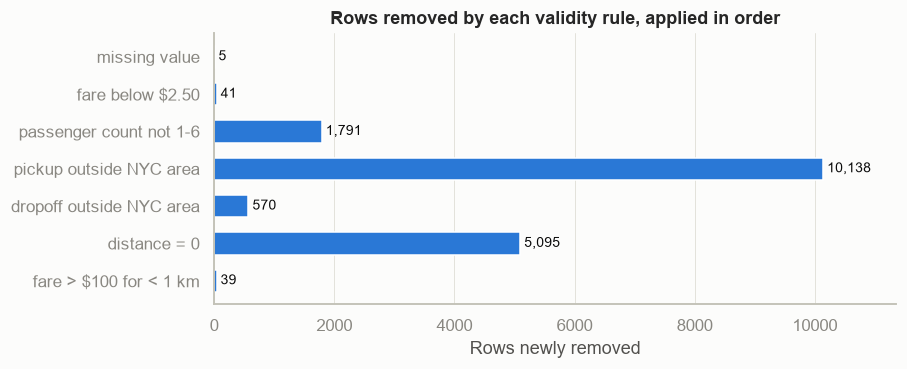

In [9]:
rules = {
    'missing value': df[raw.columns].isna().any(axis=1),
    f'fare below ${MIN_FARE:.2f}': df[TARGET] < MIN_FARE,
    'passenger count not 1-6': ~df['passenger_count'].between(1, 6),
    'pickup outside NYC area': ~in_box(df['pickup_lat'], df['pickup_lon'], NYC_BOX),
    'dropoff outside NYC area': ~in_box(df['dropoff_lat'], df['dropoff_lon'], NYC_BOX),
    'distance = 0': df['distance'] == 0,
    'fare > $100 for < 1 km': (df[TARGET] > 100) & (df['distance'] < 1),
}

keep = pd.Series(True, index=df.index)
rows = []
for name, mask in rules.items():
    newly = int((mask & keep).sum())
    keep &= ~mask
    rows.append({'rule': name, 'rows breaking it': int(mask.sum()), 'newly removed': newly, 'rows left': int(keep.sum())})
attrition = pd.DataFrame(rows).set_index('rule')
display(attrition.style.format('{:,}'))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(attrition.index[::-1], attrition['newly removed'][::-1], color=BLUE, height=0.6)
for y_pos, value in enumerate(attrition['newly removed'][::-1]):
    ax.text(value, y_pos, f' {value:,}', va='center', color=INK, fontsize=9)
ax.set_xlabel('Rows newly removed')
ax.set_title('Rows removed by each validity rule, applied in order')
ax.grid(axis='y', visible=False)
ax.margins(x=0.12)
plt.show()

## 3. Cleaning

The rules above are applied to get `clean`. Because they are fixed domain rules and nothing is estimated from the data, applying them before the train/test split does not leak information.

Three helper columns are added **for the EDA only**. `fare_per_km` contains the target, so it must never be a model feature — the model's inputs are restricted to `RAW_FEATURES` in section 5.

In [10]:
clean = df[keep].copy()
print(f"Kept {len(clean):,} of {len(df):,} rows ({len(clean) / len(df):.1%}); removed {len(df) - len(clean):,}.")

pickup_airport_km = pd.DataFrame({
    name: haversine_km(clean['pickup_latitude'], clean['pickup_longitude'], np.radians(lat), np.radians(lon))
    for name, (lat, lon) in AIRPORTS.items()})
clean['nearest_airport_km'] = pickup_airport_km.min(axis=1)
clean['airport_pickup'] = np.where(clean['nearest_airport_km'] <= AIRPORT_RADIUS_KM, 'Airport pickup', 'Other pickup')
clean['fare_per_km'] = clean[TARGET] / clean['distance']

assert clean[raw.columns].isna().sum().sum() == 0 and clean.duplicated(subset=raw.columns.tolist()).sum() == 0
print("No missing values and no duplicate rows remain.")

Kept 482,321 of 500,000 rows (96.5%); removed 17,679.


No missing values and no duplicate rows remain.


## 4. Exploratory data analysis

Everything from here uses `clean`. Two small helpers are used throughout:

* `group_summary` — trips, quartiles, median and mean of a value per group.
* `eta_squared` — the share of the value's variance that the grouping explains (0 = none, 1 = all). With almost half a million rows every difference is "statistically significant", so a p-value says nothing; the effect size says whether the difference is big enough to matter.

Group plots show a **dot for the median and a bar for the middle 50%** of trips.

In [11]:
def group_summary(data, by, value):
    grouped = data.groupby(by, observed=True)[value]
    return pd.DataFrame({'trips': grouped.size(), 'q25': grouped.quantile(0.25), 'median': grouped.median(),
                         'q75': grouped.quantile(0.75), 'mean': grouped.mean()})


def eta_squared(data, by, value):
    grouped = data.groupby(by, observed=True)[value]
    grand_mean = data[value].mean()
    between = (grouped.size() * (grouped.mean() - grand_mean) ** 2).sum()
    return between / ((data[value] - grand_mean) ** 2).sum()


def plot_group_summary(ax, summary, xlabel, ylabel, title, color=BLUE):
    x = np.arange(len(summary))
    ax.vlines(x, summary['q25'], summary['q75'], color=color, lw=3, alpha=0.4)
    ax.plot(x, summary['median'], 'o', color=color, ms=8)
    ax.set_xticks(x)
    ax.set_xticklabels([str(i) for i in summary.index])
    ax.set_ylim(0, summary['q75'].max() * 1.2)
    ax.margins(x=0.15)
    ax.grid(axis='x', visible=False)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)


def answer_group_question(by, value, value_label):
    summary = group_summary(clean, by, value)
    display(summary.round(2))
    fig, ax = plt.subplots(figsize=(7, 3.6))
    plot_group_summary(ax, summary, by, value_label, f'{value_label} by {by} (dot = median, bar = middle 50%)')
    plt.show()
    eta = eta_squared(clean, by, value)
    print(f"Medians range from {summary['median'].min():.2f} to {summary['median'].max():.2f}; "
          f"means from {summary['mean'].min():.2f} to {summary['mean'].max():.2f}.")
    print(f"{by} explains {eta:.4%} of the variance in {value} (eta squared = {eta:.5f}).")

### 4.1 The target: `fare_amount`

Left: fares on their natural scale (the top 0.5% are cut off so the bulk is visible). Right: the same fares on a log scale, which is what a model with a log-transformed target sees.

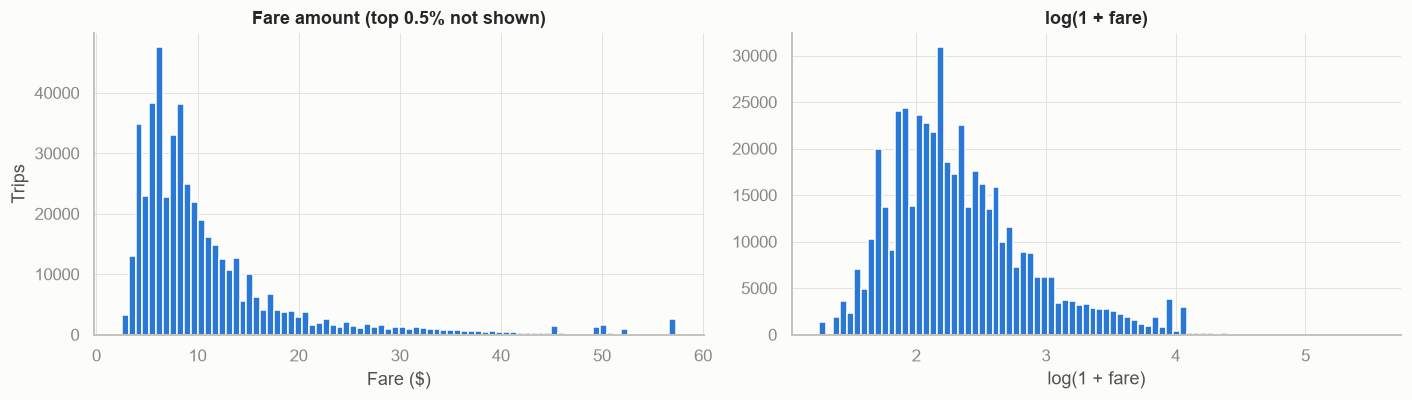

,count,mean,std,min,1%,25%,50%,75%,99%,max
fare_amount,482321.0,11.33,9.47,2.5,3.3,6.0,8.5,12.5,52.0,250.0


Skewness: 3.23 raw, 0.97 after log(1 + fare)
Most common fares above $40:
fare_amount
57.3    2077
49.8    1454
45.0    1263
49.6     943
52.0     896


In [12]:
fare = clean[TARGET]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(fare[fare <= fare.quantile(0.995)], bins=80, color=BLUE)
axes[0].set_title('Fare amount (top 0.5% not shown)')
axes[0].set_xlabel('Fare ($)')
axes[0].set_ylabel('Trips')
axes[1].hist(np.log1p(fare), bins=80, color=BLUE)
axes[1].set_title('log(1 + fare)')
axes[1].set_xlabel('log(1 + fare)')
plt.tight_layout()
plt.show()

display(fare.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(2).to_frame().T)
print(f"Skewness: {fare.skew():.2f} raw, {np.log1p(fare).skew():.2f} after log(1 + fare)")
print("Most common fares above $40:")
print(fare[fare > 40].round(1).value_counts().head(5).to_string())

**Result.** The fare is strongly right-skewed: the median is \$8.50, the mean \$11.33, the 99th percentile \$52 and the maximum \$250. The skewness falls from 3.23 to 0.97 after the log transform, which is why a log-target model is included among the baselines.

The most common fares above \$40 are \$57.3 (2,077 trips), \$49.8 (1,454), \$45.0 (1,263), \$49.6 (943) and \$52.0 (896). \$45 and \$52 are the **flat Manhattan–JFK fares** before and after September 2012. The other three match the same flat fares plus a bridge or tunnel toll (45 + 4.80, 45 + 4.57 and 52 + 5.33), which indicates that `fare_amount` includes tolls. These trips cost the same regardless of distance, so a model has to learn them from location.

### 4.2 Feature distributions

All numeric features in one figure. Continuous features are clipped to their 1st–99th percentile; discrete ones are shown as counts.

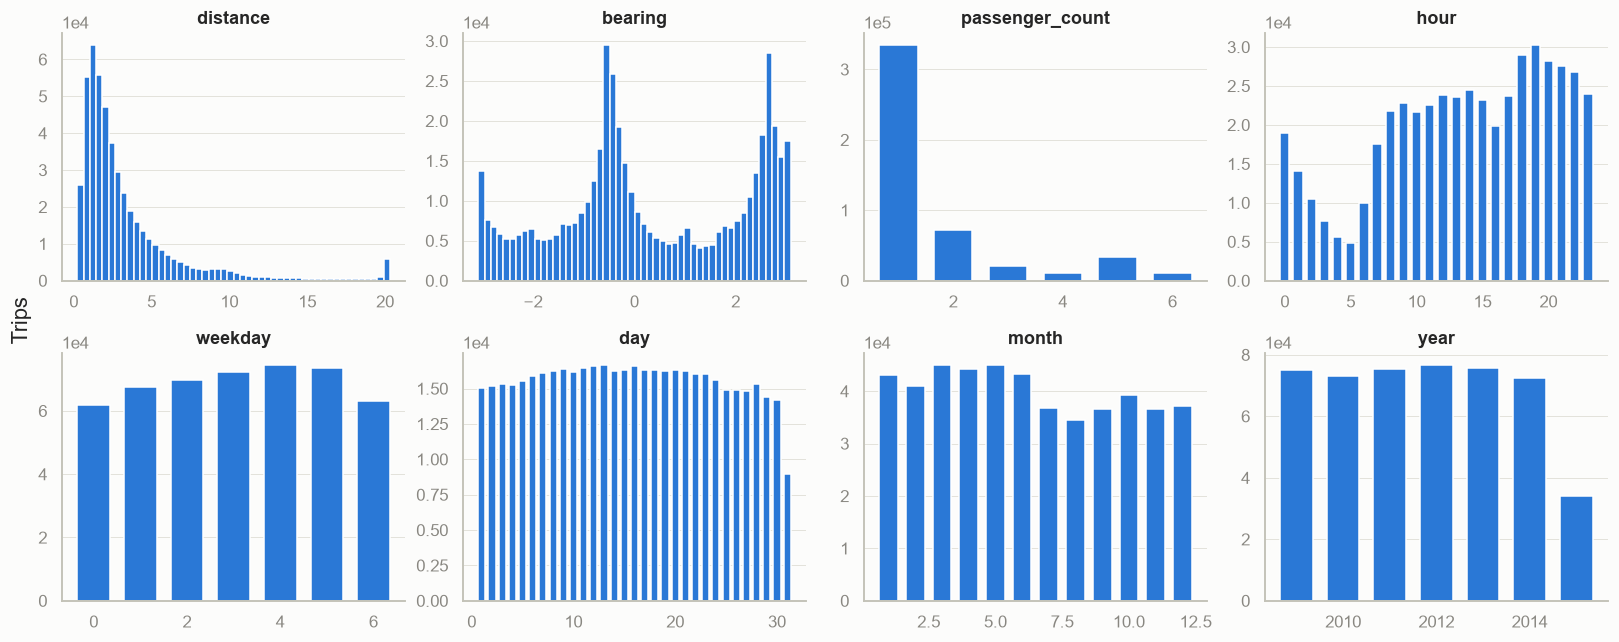

,min,median,max,skew
distance,0.00,2.18,51.14,2.91
bearing,-3.14,-0.12,3.14,-0.04
passenger_count,1.00,1.00,6.00,1.98
hour,0.00,14.00,23.00,-0.44
weekday,0.00,3.00,6.00,-0.04
day,1.00,16.00,31.00,0.02
month,1.00,6.00,12.00,0.11
year,2009.00,2012.00,2015.00,0.06


In [13]:
continuous = ['distance', 'bearing']
discrete = ['passenger_count', 'hour', 'weekday', 'day', 'month', 'year']

fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, col in zip(axes.ravel(), continuous + discrete):
    if col in continuous:
        low, high = clean[col].quantile([0.01, 0.99])
        ax.hist(clean[col].clip(low, high), bins=50, color=BLUE)
    else:
        counts = clean[col].value_counts().sort_index()
        ax.bar(counts.index, counts.values, color=BLUE, width=0.7)
    ax.set_title(col)
    ax.grid(axis='x', visible=False)
    ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
fig.supylabel('Trips')
plt.tight_layout()
plt.show()

display(clean[continuous + discrete].agg(['min', 'median', 'max', 'skew']).T.round(2))

### 4.3 Fare against distance

Left: every cleaned trip, binned into hexagons (darker = more trips, log scale), with the median fare per distance band on top. Right: fare per km, which shows how the fixed starting charge makes short trips expensive per km.

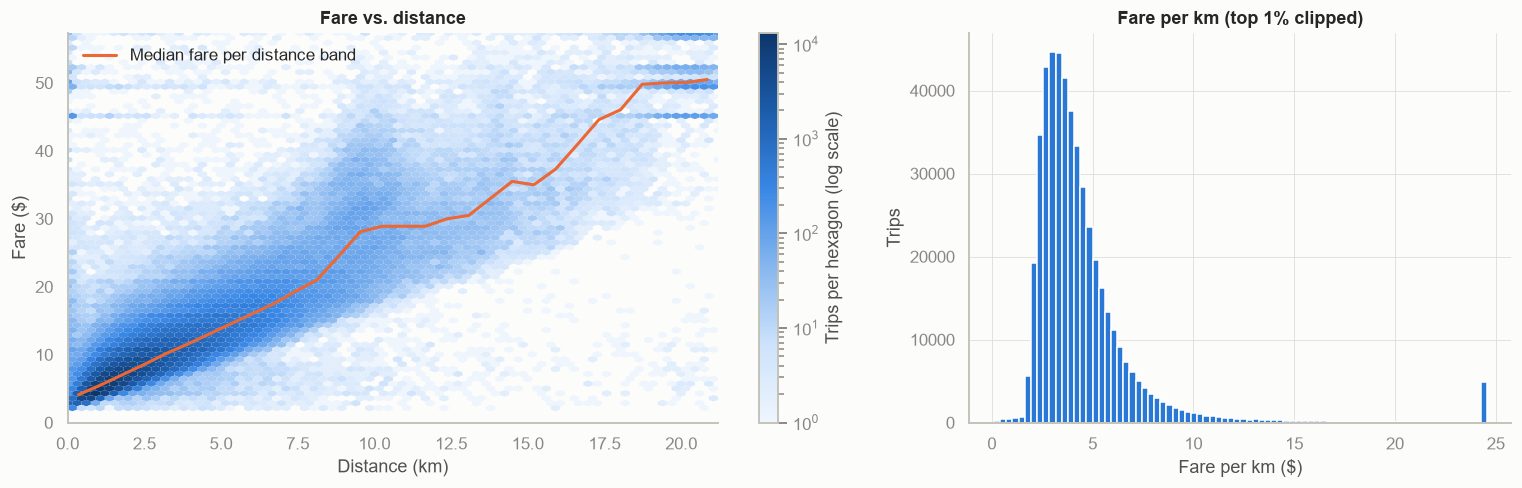

Pearson r = 0.881, Spearman rho = 0.858
Straight-line fit: fare = 3.51 + 2.33 x km
Median fare per km: 3.82


In [14]:
x_max, y_max = clean['distance'].quantile(0.995), clean[TARGET].quantile(0.995)
bands = pd.cut(clean['distance'], np.linspace(0, x_max, 31))
band_median = clean.groupby(bands, observed=True)[TARGET].median()
band_centre = [interval.mid for interval in band_median.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={'width_ratios': [1.5, 1]})
shown = clean[(clean['distance'] <= x_max) & (clean[TARGET] <= y_max)]
hb = axes[0].hexbin(shown['distance'], shown[TARGET], gridsize=70, bins='log', cmap=SEQ, mincnt=1,
                    extent=(0, x_max, 0, y_max), linewidths=0)
axes[0].plot(band_centre, band_median.values, color=ORANGE, lw=2, label='Median fare per distance band')
axes[0].set_xlim(0, x_max)
axes[0].set_ylim(0, y_max)
axes[0].set_xlabel('Distance (km)')
axes[0].set_ylabel('Fare ($)')
axes[0].set_title('Fare vs. distance')
axes[0].legend(loc='upper left', frameon=False)
axes[0].grid(False)
fig.colorbar(hb, ax=axes[0], label='Trips per hexagon (log scale)')

axes[1].hist(clean['fare_per_km'].clip(upper=clean['fare_per_km'].quantile(0.99)), bins=80, color=BLUE)
axes[1].set_xlabel('Fare per km ($)')
axes[1].set_ylabel('Trips')
axes[1].set_title('Fare per km (top 1% clipped)')
plt.tight_layout()
plt.show()

slope, intercept = np.polyfit(clean['distance'], clean[TARGET], 1)
print(f"Pearson r = {clean['distance'].corr(clean[TARGET]):.3f}, "
      f"Spearman rho = {clean['distance'].corr(clean[TARGET], method='spearman'):.3f}")
print(f"Straight-line fit: fare = {intercept:.2f} + {slope:.2f} x km")
print(f"Median fare per km: {clean['fare_per_km'].median():.2f}")

**Result.** Distance explains most of the fare: Pearson r = 0.881 and Spearman ρ = 0.858. The straight-line fit is fare = 3.51 + 2.33 × km, which is the "taxi meter" used as a baseline in section 7, and the median fare per km is \$3.82.

The relationship is not a straight line everywhere. The orange median line rises steadily up to about 9 km, flattens at around \$29–30 between 10 and 13 km, and levels off near \$50 beyond 18 km. The horizontal bands at \$45, \$50, \$52 and \$57 are the flat JFK fares, which ignore distance. A linear model is systematically wrong in those regions, so a tree-based model has room to do better.

### 4.4 Fares and demand over time

Fares are not stable over the six years: NYC raised taxi rates on 4 September 2012 (dashed line). Two separate panels are used because fare and trip count are on different scales.

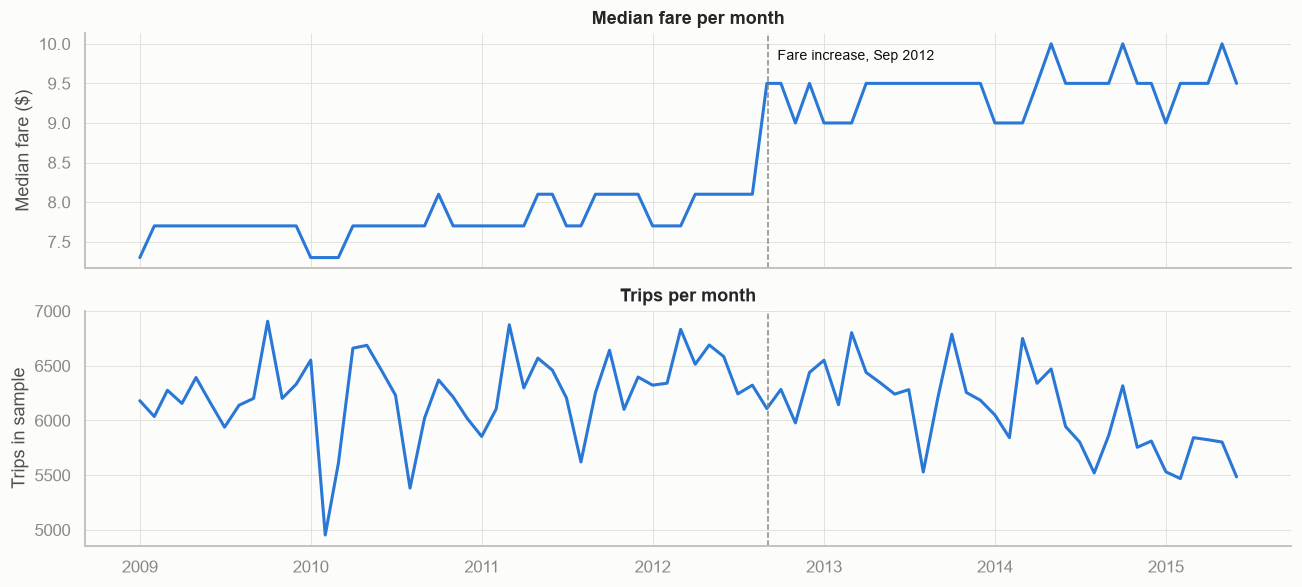

Median fare before / after 4 Sep 2012: 7.70 / 9.50
Median fare per km before / after:     3.53 / 4.20


In [15]:
monthly = clean.set_index('pickup_datetime').resample('MS')[TARGET].agg(['median', 'size'])

fig, axes = plt.subplots(2, 1, figsize=(12, 5.5), sharex=True)
axes[0].plot(monthly.index, monthly['median'], color=BLUE, lw=2)
axes[0].set_ylabel('Median fare ($)')
axes[0].set_title('Median fare per month')
axes[1].plot(monthly.index, monthly['size'], color=BLUE, lw=2)
axes[1].set_ylabel('Trips in sample')
axes[1].set_title('Trips per month')
for ax in axes:
    ax.axvline(FARE_CHANGE, color=MUTED, ls='--', lw=1)
axes[0].annotate('Fare increase, Sep 2012', (FARE_CHANGE, monthly['median'].max()), xytext=(6, -4),
                 textcoords='offset points', color=INK, fontsize=9, va='top')
plt.tight_layout()
plt.show()

before = clean.loc[clean['pickup_datetime'] < FARE_CHANGE]
after = clean.loc[clean['pickup_datetime'] >= FARE_CHANGE]
print(f"Median fare before / after 4 Sep 2012: {before[TARGET].median():.2f} / {after[TARGET].median():.2f}")
print(f"Median fare per km before / after:     {before['fare_per_km'].median():.2f} / {after['fare_per_km'].median():.2f}")

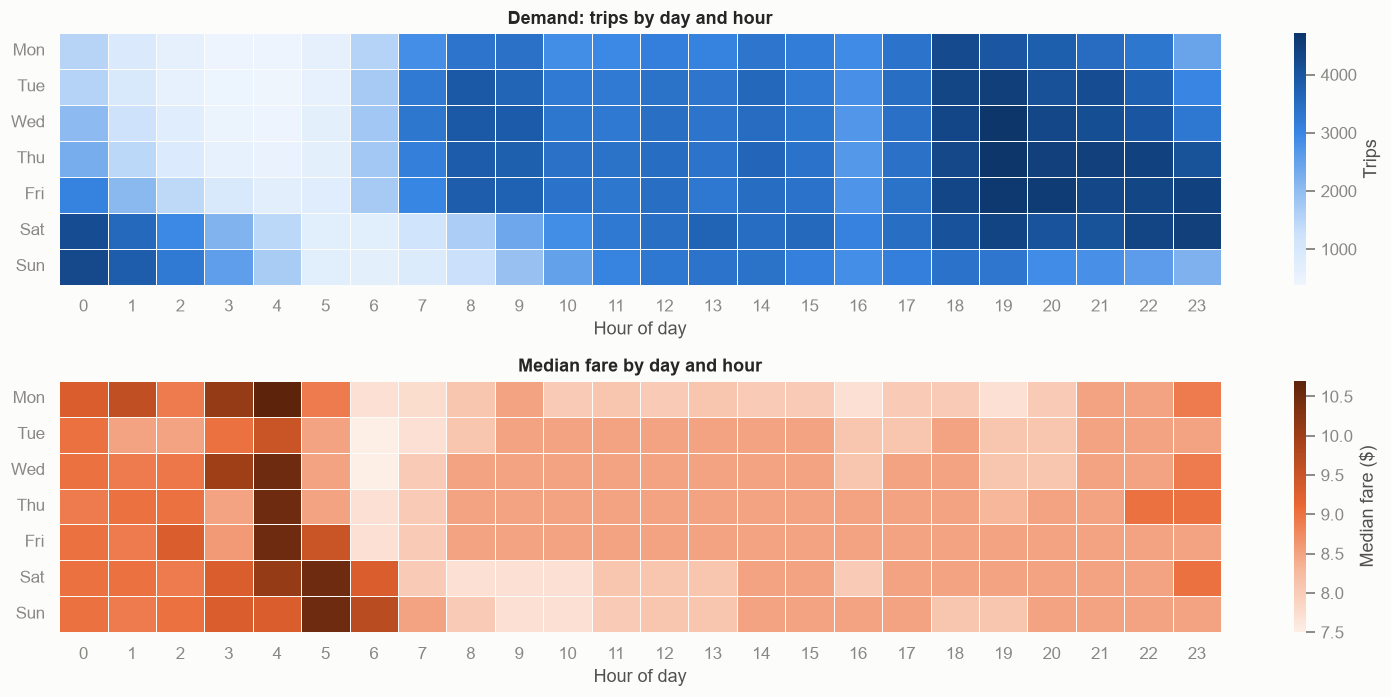

Busiest slot: Wed 19:00 (4,714 trips)
Highest median fare: Mon 4:00 (10.70)


In [16]:
trips_by_slot = clean.groupby(['weekday', 'hour']).size().unstack().rename(index=dict(enumerate(DAYS)))
fare_by_slot = clean.groupby(['weekday', 'hour'])[TARGET].median().unstack().rename(index=dict(enumerate(DAYS)))

fig, axes = plt.subplots(2, 1, figsize=(14, 6.5))
sns.heatmap(trips_by_slot, cmap=SEQ, ax=axes[0], linewidths=0.5, linecolor=SURFACE, cbar_kws={'label': 'Trips'})
axes[0].set_title('Demand: trips by day and hour')
sns.heatmap(fare_by_slot, cmap=SEQ_WARM, ax=axes[1], linewidths=0.5, linecolor=SURFACE, cbar_kws={'label': 'Median fare ($)'})
axes[1].set_title('Median fare by day and hour')
for ax in axes:
    ax.set_xlabel('Hour of day')
    ax.set_ylabel('')
    ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.show()

busy_day, busy_hour = trips_by_slot.stack().idxmax()
fare_day, fare_hour = fare_by_slot.stack().idxmax()
print(f"Busiest slot: {busy_day} {busy_hour}:00 ({int(trips_by_slot.stack().max()):,} trips)")
print(f"Highest median fare: {fare_day} {fare_hour}:00 ({fare_by_slot.stack().max():.2f})")

**Result.** The median monthly fare steps from about \$8.10 to \$9.50 exactly at the dashed line. The median fare is \$7.70 before 4 September 2012 and \$9.50 after, and the median fare per km rises from \$3.53 to \$4.20 (+19%). The *same trip costs more after 2012*, so the model needs the date (`year`, `time_index`) and a test set with the same mix of periods as training. Trips per month stay between about 5,400 and 6,900, apart from a dip to about 5,000 in February 2010.

In the heatmaps, the busiest slot is Wednesday 19:00 (4,714 trips) and weekday evenings from 18:00 to 22:00 are the busiest block. At weekends the demand moves to the hours after midnight on Saturday and Sunday, which justifies `weekday` and `is_weekend`. The highest median fare is Monday 4:00 (\$10.70), and the 4:00–5:00 band is both the most expensive and the quietest: busy hours are not expensive hours.

### 4.5 Which features move the fare at all?

Each feature is treated as a grouping and scored by eta squared — the share of fare variance it explains on its own. Distance is included (cut into ten equal-sized bands) as the yardstick. The axis is logarithmic because the values span several orders of magnitude.

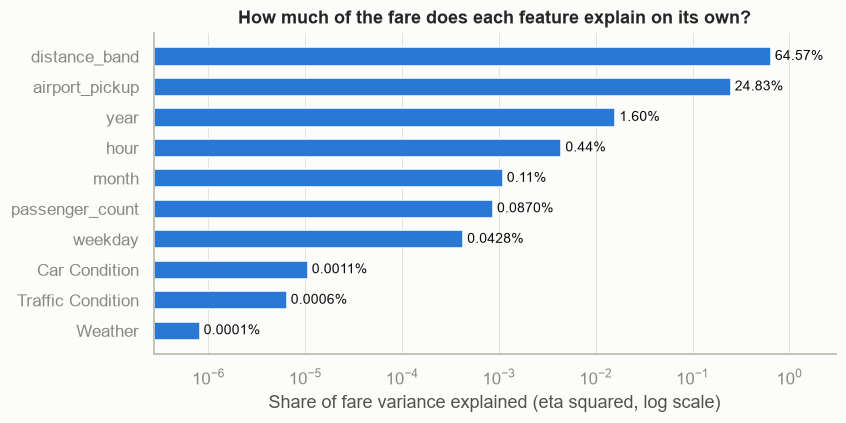

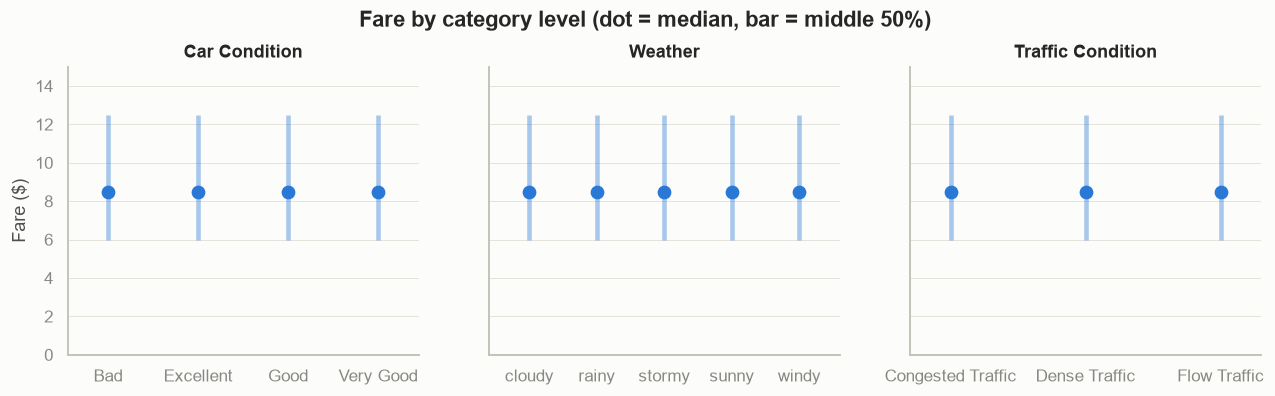

share of trips
Car Condition     Very Good                  0.2505
                  Bad                        0.2500
                  Good                       0.2499
                  Excellent                  0.2496
Weather           sunny                      0.2008
                  rainy                      0.2001
                  stormy                     0.2000
                  cloudy                     0.1999
                  windy                      0.1992
Traffic Condition Congested Traffic          0.3338
                  Flow Traffic               0.3331
                  Dense Traffic              0.3331

In [17]:
effect_data = clean.assign(distance_band=pd.qcut(clean['distance'], 10))
groupings = ['distance_band', 'airport_pickup', 'year', 'hour', 'weekday', 'month', 'passenger_count'] + CAT_COLS
effects = pd.Series({col: eta_squared(effect_data, col, TARGET) for col in groupings}).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(effects.index, effects.values, color=BLUE, height=0.6)
for y_pos, value in enumerate(effects.values):
    ax.text(value, y_pos, f' {value:.2%}' if value >= 0.001 else f' {value:.4%}', va='center', color=INK, fontsize=9)
ax.set_xscale('log')
ax.set_xlim(max(effects.min(), 1e-7) / 3, 3)
ax.set_xlabel('Share of fare variance explained (eta squared, log scale)')
ax.set_title('How much of the fare does each feature explain on its own?')
ax.grid(axis='y', visible=False)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
for ax, col in zip(axes, CAT_COLS):
    plot_group_summary(ax, group_summary(clean, col, TARGET), '', 'Fare ($)' if ax is axes[0] else '', col)
fig.suptitle('Fare by category level (dot = median, bar = middle 50%)', y=1.03, fontweight='bold')
plt.show()

display(pd.concat({col: clean[col].value_counts(normalize=True).round(4) for col in CAT_COLS}).to_frame('share of trips'))

**Result.** Share of fare variance explained by each feature on its own:

| Feature | Share |
|---|---|
| Distance (ten bands) | 64.57% |
| Airport pickup | 24.83% |
| Year | 1.60% |
| Hour | 0.44% |
| Month | 0.11% |
| Passenger count | 0.087% |
| Weekday | 0.043% |
| Car Condition | 0.0011% |
| Traffic Condition | 0.0006% |
| Weather | 0.0001% |

`Car Condition`, `Weather` and `Traffic Condition` are roughly 40 to 400 times weaker than the weakest of the other features. Their levels are also split almost perfectly evenly (25% each, 20% each and 33.3% each), so they behave like labels assigned at random rather than observed conditions. They are still passed to the models, and the permutation importance in section 9.3 confirms from the model's side that they are not used.

### 4.6 Relationships between features

**Spearman correlation** (rank-based, so robust to the skew seen above) between all numeric columns, ordered by the strength of their link with the fare. Blue is negative, red positive, grey none.

Correlation only sees monotonic relationships. A pickup longitude is not "more fare the further east" — it matters because of *where* it is. **Mutual information** (second chart) measures any kind of dependence and is the better guide to which raw columns carry signal.

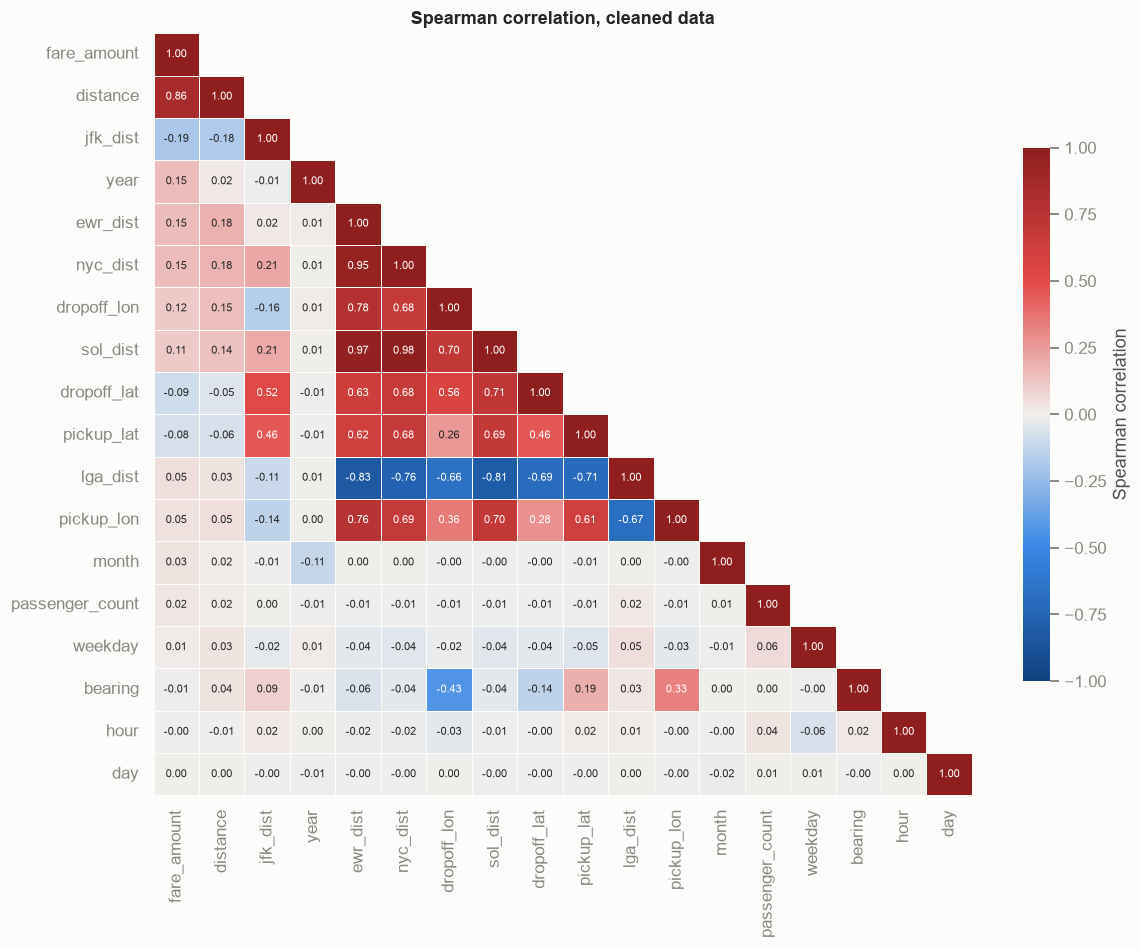

Most strongly correlated feature pairs (redundant information):
sol_dist     nyc_dist    0.984
             ewr_dist    0.970
nyc_dist     ewr_dist    0.953
lga_dist     ewr_dist   -0.828
             sol_dist   -0.811
dropoff_lon  ewr_dist    0.777
lga_dist     nyc_dist   -0.764
pickup_lon   ewr_dist    0.756


In [18]:
corr_cols = [TARGET, 'distance', 'passenger_count', 'hour', 'weekday', 'day', 'month', 'year', 'bearing',
             'pickup_lat', 'pickup_lon', 'dropoff_lat', 'dropoff_lon', 'jfk_dist', 'lga_dist', 'ewr_dist', 'sol_dist', 'nyc_dist']
corr = clean[corr_cols].corr(method='spearman')
order = corr[TARGET].abs().sort_values(ascending=False).index
corr = corr.loc[order, order]

fig, ax = plt.subplots(figsize=(12, 9))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), cmap=DIVERGING, vmin=-1, vmax=1, center=0,
            annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=0.5, linecolor=SURFACE,
            cbar_kws={'label': 'Spearman correlation', 'shrink': 0.7}, ax=ax)
ax.set_title('Spearman correlation, cleaned data')
ax.grid(False)
plt.show()

pairs = corr.where(np.tril(np.ones_like(corr, dtype=bool), k=-1)).stack()
pairs = pairs[[TARGET not in pair for pair in pairs.index]]
print("Most strongly correlated feature pairs (redundant information):")
print(pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(8).round(3).to_string())

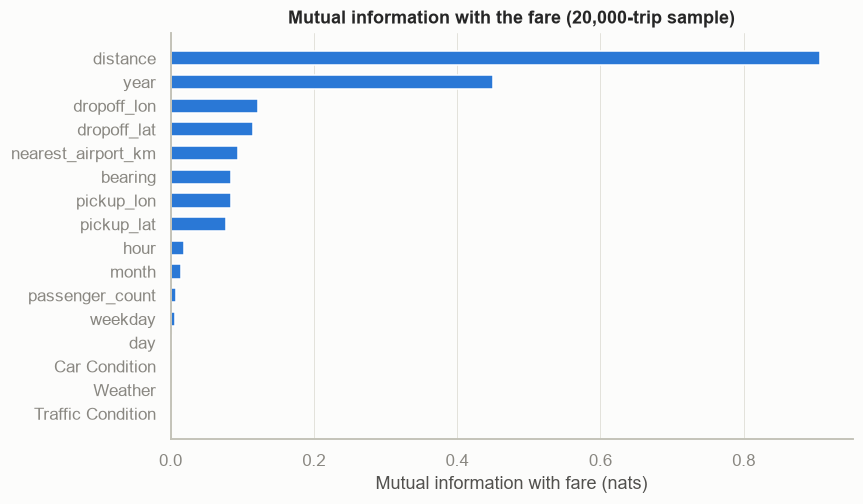

In [19]:
mi_cols = ['distance', 'pickup_lat', 'pickup_lon', 'dropoff_lat', 'dropoff_lon', 'nearest_airport_km', 'bearing',
           'year', 'month', 'day', 'weekday', 'hour', 'passenger_count'] + CAT_COLS
mi_discrete = ['year', 'month', 'day', 'weekday', 'hour', 'passenger_count'] + CAT_COLS
mi_sample = clean.sample(min(MI_SAMPLE, len(clean)), random_state=RANDOM_STATE)
mi_X = mi_sample[mi_cols].copy()
for col in CAT_COLS:
    mi_X[col] = mi_X[col].astype('category').cat.codes

mi = pd.Series(mutual_info_regression(mi_X, mi_sample[TARGET], discrete_features=[c in mi_discrete for c in mi_cols],
                                      random_state=RANDOM_STATE), index=mi_cols).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(mi.index, mi.values, color=BLUE, height=0.6)
ax.set_xlabel('Mutual information with fare (nats)')
ax.set_title(f'Mutual information with the fare ({len(mi_sample):,}-trip sample)')
ax.grid(axis='y', visible=False)
plt.show()

**Result.** In the correlation matrix, `sol_dist`, `nyc_dist` and `ewr_dist` are near-duplicates of each other (0.984, 0.970 and 0.953), and `lga_dist` is strongly negatively correlated with all three (−0.76 to −0.83). The provided landmark columns therefore repeat the same information.

In the mutual-information chart, `distance` is far ahead (about 0.9 nats). `year` is second (about 0.45), well above what its correlation with fare (0.151) suggested: the fare schedule depends on the date in a way a rank correlation does not capture. The coordinates, `nearest_airport_km` and `bearing` form the next group (about 0.08–0.12) even though `pickup_lon` has a Spearman correlation with fare of only 0.046. That is *location* signal (airports, flat fares, boroughs), which only a non-linear model or engineered distances can use. `hour`, `month`, `passenger_count` and `weekday` are close to zero, and `day` and the three category columns are at zero in both views.

### 4.7 The eight questions

#### Q1) Is a higher passenger count associated with a higher fare?

,trips,q25,median,q75,mean
passenger_count,,,,,
1,334721,6.0,8.5,12.5,11.18
2,71749,6.1,8.5,13.0,11.81
3,21110,6.1,8.5,12.9,11.48
4,10271,6.1,8.5,13.0,11.70
5,34178,6.0,8.5,12.5,11.24
6,10292,6.5,9.0,14.0,12.38


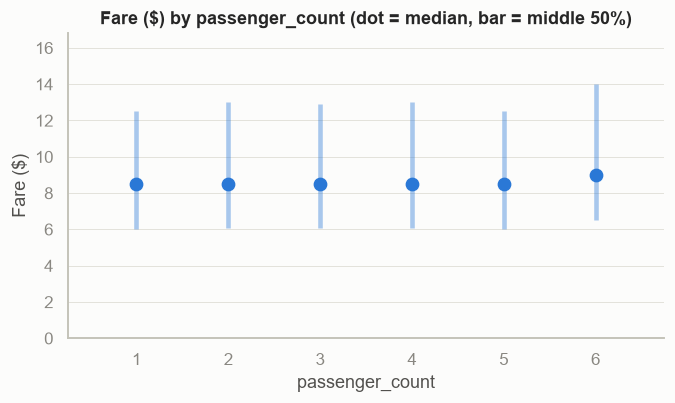

Medians range from 8.50 to 9.00; means from 11.18 to 12.38.
passenger_count explains 0.0870% of the variance in fare_amount (eta squared = 0.00087).
Spearman correlation with fare: 0.024


In [20]:
answer_group_question('passenger_count', TARGET, 'Fare ($)')
print(f"Spearman correlation with fare: {clean['passenger_count'].corr(clean[TARGET], method='spearman'):.3f}")

**Answer: no.** The median fare is \$8.50 for one to five passengers and \$9.00 for six, and the middle-50% bars overlap almost entirely. Passenger count explains 0.087% of the fare variance and its Spearman correlation with fare is 0.024. This matches how NYC taxis charge: per trip, not per person. The slightly higher fares for six passengers (mean \$12.38 against \$11.18 for one) are too small to matter for prediction.

#### Q2) Does car condition influence the fare?

,trips,q25,median,q75,mean
Car Condition,,,,,
Bad,120577,6.0,8.5,12.5,11.29
Excellent,120384,6.0,8.5,12.5,11.32
Good,120530,6.0,8.5,12.5,11.32
Very Good,120830,6.0,8.5,12.5,11.37


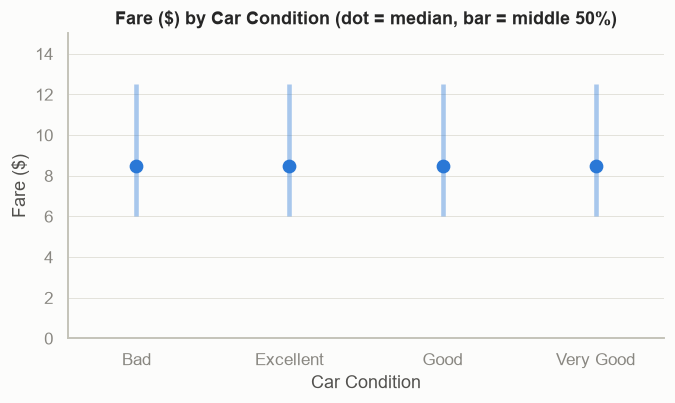

Medians range from 8.50 to 8.50; means from 11.29 to 11.37.
Car Condition explains 0.0011% of the variance in fare_amount (eta squared = 0.00001).


In [21]:
answer_group_question('Car Condition', TARGET, 'Fare ($)')

**Answer: no.** Every car-condition level has the same quartiles (\$6.00, \$8.50, \$12.50), the means differ by 8 cents (\$11.29 to \$11.37), and the column explains 0.0011% of the fare variance. Car condition is not a pricing factor in this data.

#### Q3) At what hour of the day are fares highest?

Mean and median fare per hour (top) and mean trip distance per hour (bottom). Comparing the panels shows whether an expensive hour is expensive because trips are longer.

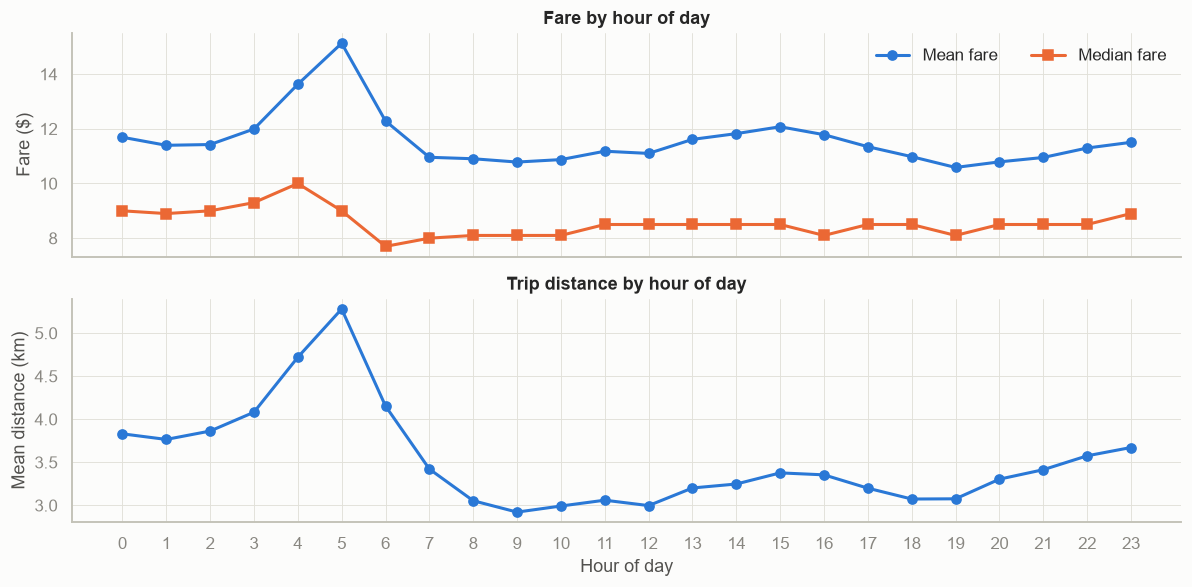

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
mean_fare,11.69,11.40,11.42,11.99,13.63,15.13,12.29,10.96,10.90,10.78,...,11.82,12.07,11.78,11.34,10.98,10.59,10.79,10.95,11.30,11.51
median_fare,9.00,8.90,9.00,9.30,10.00,9.00,7.70,8.00,8.10,8.10,...,8.50,8.50,8.10,8.50,8.50,8.10,8.50,8.50,8.50,8.90
mean_distance,3.83,3.77,3.86,4.08,4.72,5.28,4.15,3.42,3.05,2.92,...,3.25,3.38,3.35,3.20,3.07,3.08,3.30,3.41,3.58,3.67
median_fare_per_km,3.37,3.32,3.25,3.21,3.12,3.10,3.27,3.61,4.07,4.18,...,4.18,4.12,3.99,3.99,4.03,3.88,3.68,3.56,3.49,3.45
trips,18930.00,14033.00,10483.00,7627.00,5630.00,4779.00,9976.00,17575.00,21830.00,22780.00,...,24504.00,23192.00,19823.00,23752.00,29017.00,30265.00,28220.00,27607.00,26832.00,23982.00


Highest mean fare: 5:00 (15.13, mean distance 5.28 km, 4,779 trips)
Lowest mean fare:  19:00 (10.59, mean distance 3.08 km, 30,265 trips)
Highest median fare: 4:00
Correlation across hours between mean fare and mean distance: 0.89


In [22]:
by_hour = clean.groupby('hour').agg(mean_fare=(TARGET, 'mean'), median_fare=(TARGET, 'median'),
                                    mean_distance=('distance', 'mean'), median_fare_per_km=('fare_per_km', 'median'),
                                    trips=(TARGET, 'size'))

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].plot(by_hour.index, by_hour['mean_fare'], marker='o', color=BLUE, lw=2, label='Mean fare')
axes[0].plot(by_hour.index, by_hour['median_fare'], marker='s', color=ORANGE, lw=2, label='Median fare')
axes[0].set_ylabel('Fare ($)')
axes[0].set_title('Fare by hour of day')
axes[0].legend(frameon=False, ncol=2)
axes[1].plot(by_hour.index, by_hour['mean_distance'], marker='o', color=BLUE, lw=2)
axes[1].set_ylabel('Mean distance (km)')
axes[1].set_xlabel('Hour of day')
axes[1].set_title('Trip distance by hour of day')
axes[1].set_xticks(range(24))
plt.tight_layout()
plt.show()

display(by_hour.round(2).T)
top, low = by_hour['mean_fare'].idxmax(), by_hour['mean_fare'].idxmin()
print(f"Highest mean fare: {top}:00 ({by_hour.loc[top, 'mean_fare']:.2f}, mean distance {by_hour.loc[top, 'mean_distance']:.2f} km, {by_hour.loc[top, 'trips']:,} trips)")
print(f"Lowest mean fare:  {low}:00 ({by_hour.loc[low, 'mean_fare']:.2f}, mean distance {by_hour.loc[low, 'mean_distance']:.2f} km, {by_hour.loc[low, 'trips']:,} trips)")
print(f"Highest median fare: {by_hour['median_fare'].idxmax()}:00")
print(f"Correlation across hours between mean fare and mean distance: {by_hour['mean_fare'].corr(by_hour['mean_distance']):.2f}")

**Answer: around 5:00 in the morning.** The mean fare peaks at 5:00 (\$15.13) and the median at 4:00 (\$10.00). The lowest mean fare is at 19:00 (\$10.59).

The expensive hours are the hours with longer trips, not higher prices. The mean distance is 5.28 km at 5:00 against 3.08 km at 19:00, and across the 24 hours mean fare and mean distance have a correlation of 0.89. The fare per km is in fact *lowest* at 5:00 (\$3.10) and highest in the daytime (about \$4.10–4.20), when traffic is slow. At 5:00 the mean (\$15.13) is far above the median (\$9.00) with only 4,779 trips, so a small number of long trips, typically airport runs, pulls the average up.

#### Q4) Does traffic condition affect the fare?

,trips,q25,median,q75,mean
Traffic Condition,,,,,
Congested Traffic,160979,6.0,8.5,12.5,11.36
Dense Traffic,160663,6.0,8.5,12.5,11.32
Flow Traffic,160679,6.0,8.5,12.5,11.30


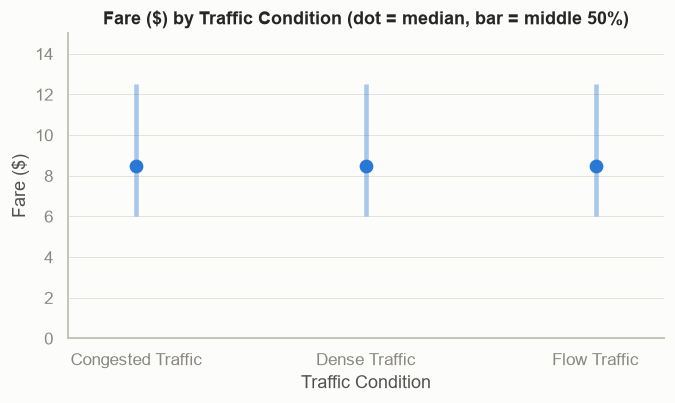

Medians range from 8.50 to 8.50; means from 11.30 to 11.36.
Traffic Condition explains 0.0006% of the variance in fare_amount (eta squared = 0.00001).


In [23]:
answer_group_question('Traffic Condition', TARGET, 'Fare ($)')

**Answer: no, not in this dataset.** All three traffic levels have the same quartiles (\$6.00, \$8.50, \$12.50), the means differ by 6 cents (\$11.30 to \$11.36), and the column explains 0.0006% of the fare variance. Real congestion does raise a metered fare, because the meter also runs on time, so this result means the `Traffic Condition` label is not connected to the actual traffic on the trip.

#### Q5) Is trip distance the strongest predictor of the fare?

In [24]:
numeric = clean[corr_cols]
strength = pd.DataFrame({
    'pearson': numeric.corr(method='pearson')[TARGET],
    'spearman': corr[TARGET],
}).drop(TARGET).sort_values('spearman', key=abs, ascending=False)
display(strength.round(3))

runner_up = strength.index[1]
print(f"Strongest: {strength.index[0]} (Spearman {strength['spearman'].iloc[0]:.3f}); "
      f"next: {runner_up} (Spearman {strength.loc[runner_up, 'spearman']:.3f})")
print(f"Distance bands alone explain {effects['distance_band']:.1%} of fare variance (section 4.5).")

,pearson,spearman
distance,0.881,0.858
jfk_dist,-0.468,-0.192
year,0.121,0.151
ewr_dist,0.407,0.151
nyc_dist,0.418,0.151
dropoff_lon,0.323,0.115
sol_dist,0.352,0.111
dropoff_lat,-0.175,-0.088
pickup_lat,-0.218,-0.078
lga_dist,0.107,0.054


Strongest: distance (Spearman 0.858); next: jfk_dist (Spearman -0.192)
Distance bands alone explain 64.6% of fare variance (section 4.5).


**Answer: yes, by a wide margin.** `distance` has a Spearman correlation of 0.858 with the fare; the next feature, `jfk_dist`, has −0.192. Distance bands alone explain 64.6% of the fare variance (4.5) and distance is also first in the mutual-information chart (4.6).

The model comparison in section 7 puts a number on it: a distance-only linear model has an MAE of \$2.34 against \$5.35 for predicting the median, a 56% reduction. All other features and non-linearity together bring it down to \$1.54.

#### Q6) At what time of day are ride requests most frequent?

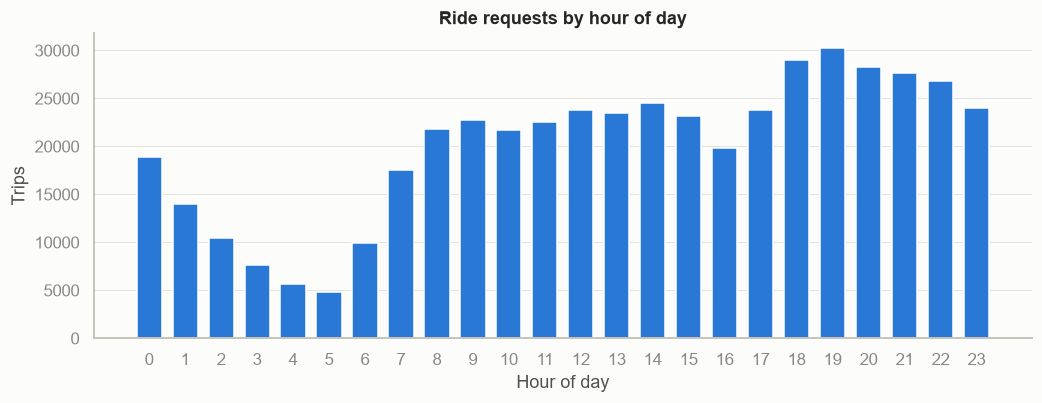

Busiest hour:  19:00 (30,265 trips)
Quietest hour: 5:00 (4,779 trips)
Peak-to-trough ratio: 6.3x
Top five hours: 19:00, 18:00, 20:00, 21:00, 22:00


In [25]:
trips_per_hour = clean['hour'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(trips_per_hour.index, trips_per_hour.values, color=BLUE, width=0.7)
ax.set_xticks(range(24))
ax.set_xlabel('Hour of day')
ax.set_ylabel('Trips')
ax.set_title('Ride requests by hour of day')
ax.grid(axis='x', visible=False)
plt.show()

print(f"Busiest hour:  {trips_per_hour.idxmax()}:00 ({trips_per_hour.max():,} trips)")
print(f"Quietest hour: {trips_per_hour.idxmin()}:00 ({trips_per_hour.min():,} trips)")
print(f"Peak-to-trough ratio: {trips_per_hour.max() / trips_per_hour.min():.1f}x")
print("Top five hours:", ", ".join(f"{h}:00" for h in trips_per_hour.sort_values(ascending=False).index[:5]))

**Answer: 19:00.** It has 30,265 trips, and the five busiest hours are 18:00 to 22:00. The quietest hour is 5:00 with 4,779 trips, a peak-to-trough ratio of 6.3×.

Compared with Q3, the busiest hour has the *lowest* mean fare (\$10.59) and one of the shortest mean distances (3.08 km): busy periods are dominated by short trips. The day × hour heatmap in 4.4 shows that this evening peak belongs to weekdays, while weekend demand is highest just after midnight.

#### Q7) Does weather influence the average trip distance?

,trips,q25,median,q75,mean
Weather,,,,,
cloudy,96422,1.27,2.16,3.94,3.35
rainy,96509,1.28,2.19,3.97,3.35
stormy,96444,1.28,2.18,3.95,3.36
sunny,96860,1.28,2.18,3.97,3.36
windy,96086,1.28,2.18,3.95,3.35


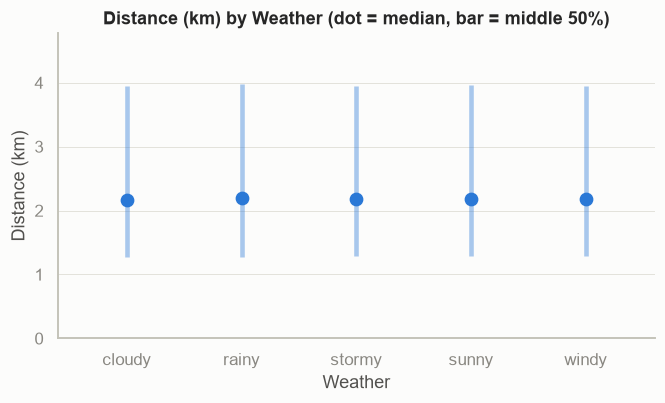

Medians range from 2.16 to 2.19; means from 3.35 to 3.36.
Weather explains 0.0002% of the variance in distance (eta squared = 0.00000).


In [26]:
answer_group_question('Weather', 'distance', 'Distance (km)')

**Answer: no.** The median distance is between 2.16 and 2.19 km for all five weather labels, the means are 3.35 to 3.36 km, and weather explains 0.0002% of the variance in distance. Trip length does not change with the weather label.

#### Q8) Are rides that start closer to airports more expensive?

A trip is an *airport pickup* if it starts within 2 km of JFK, LaGuardia or Newark (distance computed here from the pickup coordinates). Fare, distance and fare per km are compared side by side, to separate "costs more" from "costs more per km".

,trips,median_fare,mean_fare,median_distance,median_fare_per_km
airport_pickup,,,,,
Airport pickup,17072,34.25,35.96,10.87,2.83
Other pickup,465249,8.10,10.42,2.11,3.86


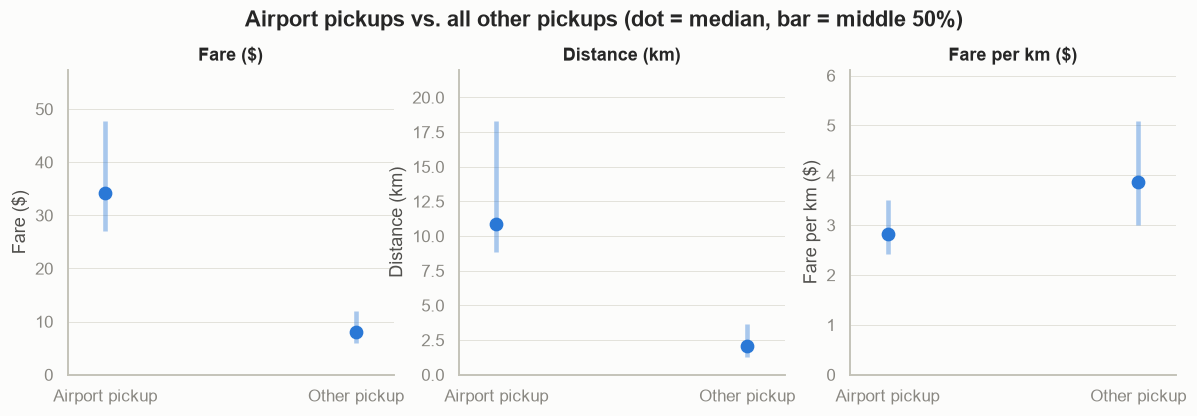

Airport pickups: 17,072 trips (3.5% of all)
Median fare:        34.25 vs 8.10  (4.2x)
Median distance:    10.87 km vs 2.11 km
Median fare per km: 2.83 vs 3.86
Spearman correlation, distance to nearest airport vs fare: -0.024


In [27]:
airport = clean.groupby('airport_pickup').agg(trips=(TARGET, 'size'), median_fare=(TARGET, 'median'), mean_fare=(TARGET, 'mean'),
                                              median_distance=('distance', 'median'), median_fare_per_km=('fare_per_km', 'median'))
display(airport.round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (value, label) in zip(axes, [(TARGET, 'Fare ($)'), ('distance', 'Distance (km)'), ('fare_per_km', 'Fare per km ($)')]):
    plot_group_summary(ax, group_summary(clean, 'airport_pickup', value), '', label, label)
fig.suptitle('Airport pickups vs. all other pickups (dot = median, bar = middle 50%)', y=1.03, fontweight='bold')
plt.show()

a, o = airport.loc['Airport pickup'], airport.loc['Other pickup']
print(f"Airport pickups: {int(a['trips']):,} trips ({a['trips'] / len(clean):.1%} of all)")
print(f"Median fare:        {a['median_fare']:.2f} vs {o['median_fare']:.2f}  ({a['median_fare'] / o['median_fare']:.1f}x)")
print(f"Median distance:    {a['median_distance']:.2f} km vs {o['median_distance']:.2f} km")
print(f"Median fare per km: {a['median_fare_per_km']:.2f} vs {o['median_fare_per_km']:.2f}")
print(f"Spearman correlation, distance to nearest airport vs fare: {clean['nearest_airport_km'].corr(clean[TARGET], method='spearman'):.3f}")

**Answer: yes per trip, no per km.** Airport pickups are 17,072 trips (3.5% of all). Their median fare is \$34.25 against \$8.10 for other pickups (4.2×), and being an airport pickup explains 24.8% of the fare variance (4.5). They are expensive because they are long: the median distance is 10.87 km against 2.11 km. Per km they are *cheaper*, \$2.83 against \$3.86, because the fixed starting charge is spread over more kilometres and the JFK flat fare caps the longest trips.

The Spearman correlation between distance to the nearest airport and fare is only −0.024. The fare does not rise gradually as a pickup gets closer to an airport; it jumps at the airport itself. That is why section 6 uses airport flags as well as distances.

### 4.8 Where trips start, end and cost the most

Maps are limited to a box around the city that includes all three airports (triangles). Colour scales are logarithmic because the busiest cells hold thousands of times more trips than quiet ones.

Pickups inside the map area:  100.0%
Dropoffs inside the map area: 99.9%


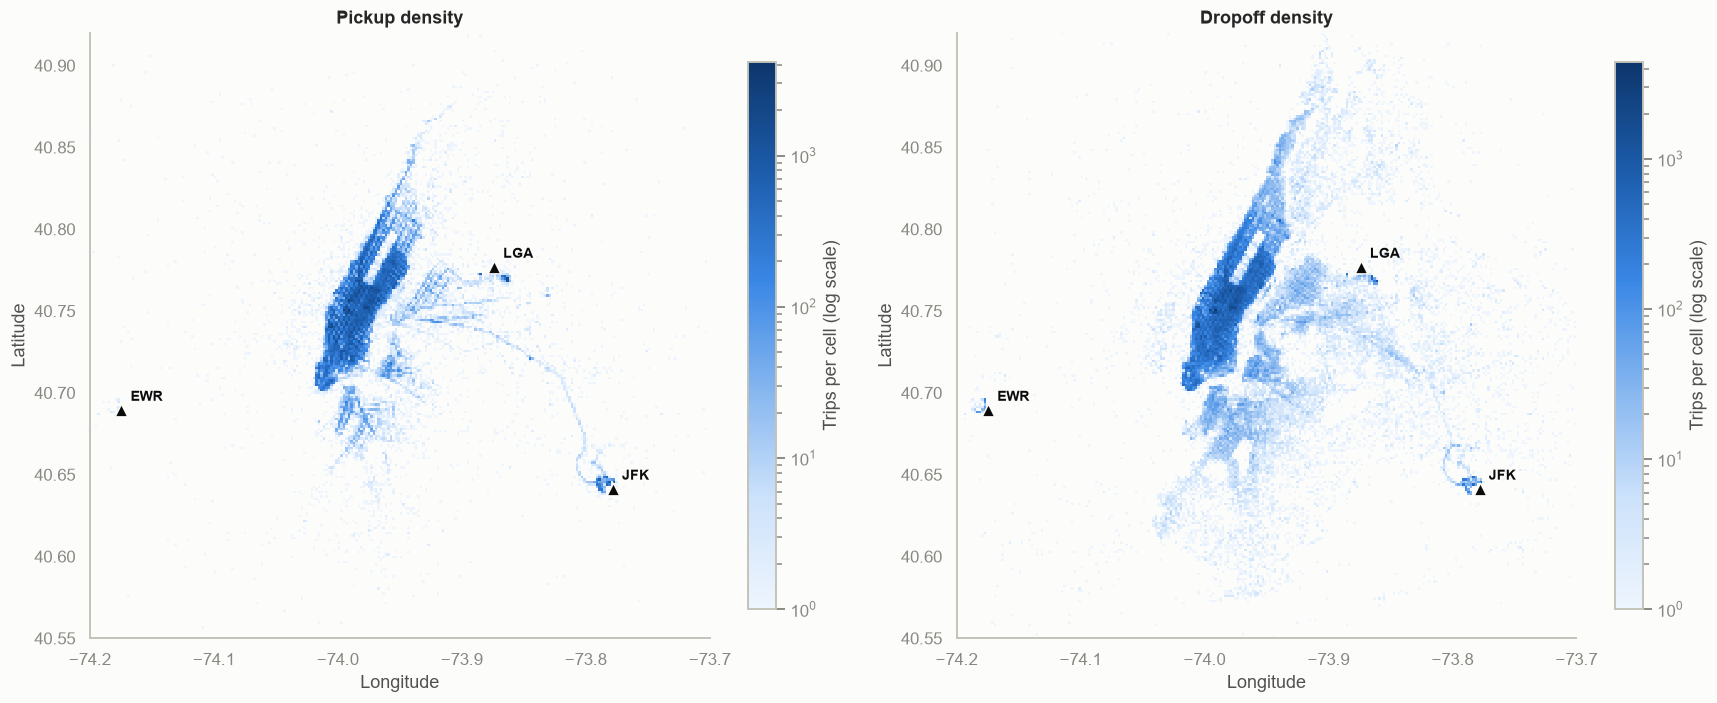

In [28]:
MAP_LAT_MIN, MAP_LAT_MAX, MAP_LON_MIN, MAP_LON_MAX = MAP_BOX
MAP_EXTENT = [MAP_LON_MIN, MAP_LON_MAX, MAP_LAT_MIN, MAP_LAT_MAX]
MAP_RANGE = [[MAP_LAT_MIN, MAP_LAT_MAX], [MAP_LON_MIN, MAP_LON_MAX]]
MAP_ASPECT = 1 / np.cos(np.radians(40.75))

pick = clean[in_box(clean['pickup_lat'], clean['pickup_lon'], MAP_BOX)]
drop = clean[in_box(clean['dropoff_lat'], clean['dropoff_lon'], MAP_BOX)]
print(f"Pickups inside the map area:  {len(pick) / len(clean):.1%}")
print(f"Dropoffs inside the map area: {len(drop) / len(clean):.1%}")


def style_map(ax, title):
    ax.set_aspect(MAP_ASPECT)
    ax.set_title(title)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    ax.grid(False)
    for name, (lat, lon) in AIRPORTS.items():
        ax.scatter(lon, lat, marker='^', s=70, c=INK, edgecolors=SURFACE, linewidths=1, zorder=3)
        ax.annotate(name, (lon, lat), xytext=(6, 6), textcoords='offset points', color=INK, fontsize=9, fontweight='bold')


fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, data, prefix in [(axes[0], pick, 'pickup'), (axes[1], drop, 'dropoff')]:
    counts, _, _ = np.histogram2d(data[f'{prefix}_lat'], data[f'{prefix}_lon'], bins=250, range=MAP_RANGE)
    counts = np.ma.masked_equal(counts, 0)
    im = ax.imshow(counts, origin='lower', extent=MAP_EXTENT, cmap=SEQ, interpolation='nearest',
                   norm=mcolors.LogNorm(vmin=1, vmax=counts.max()))
    style_map(ax, f'{prefix.capitalize()} density')
    fig.colorbar(im, ax=ax, shrink=0.75, label='Trips per cell (log scale)')
plt.tight_layout()
plt.show()

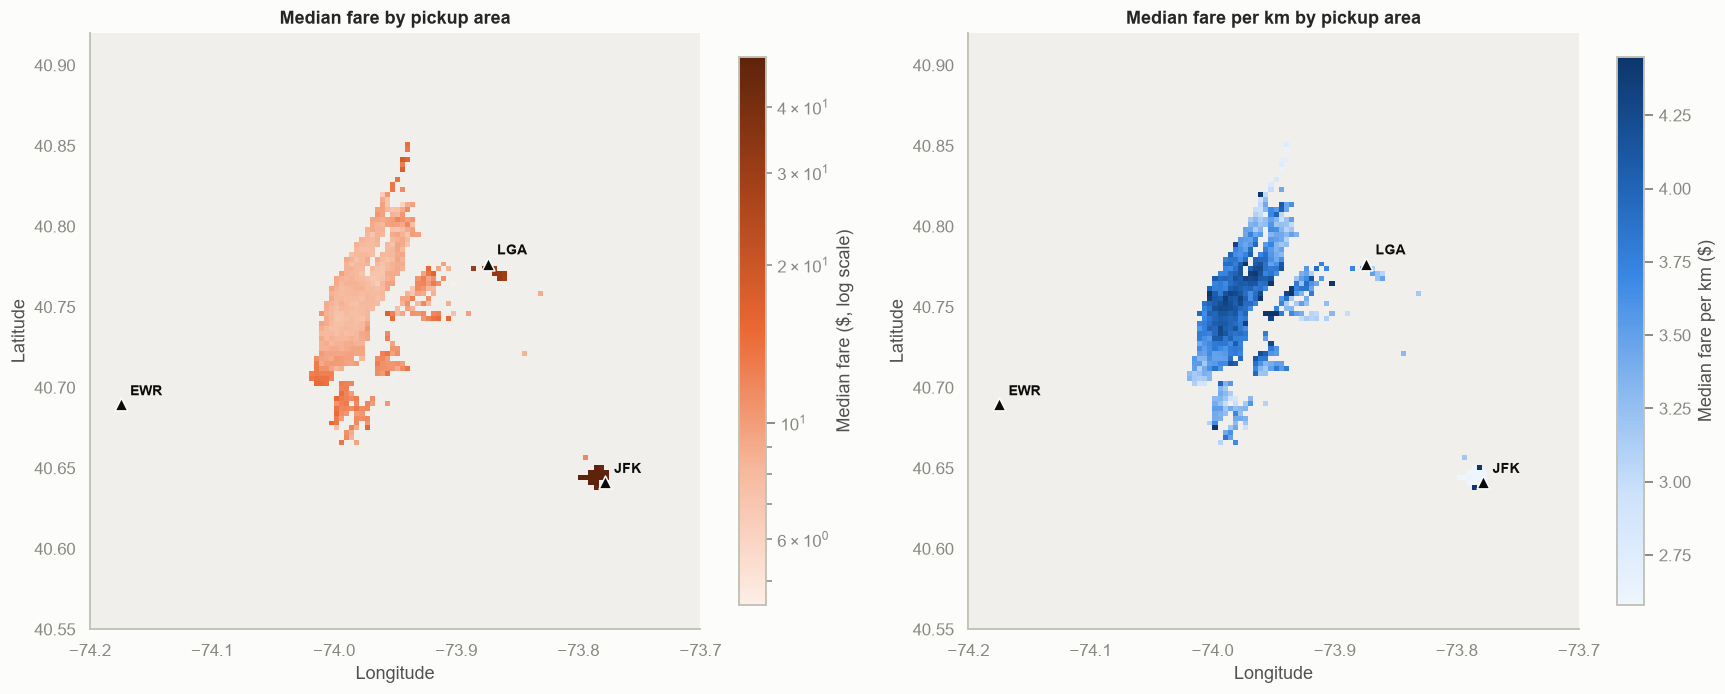

Ten busiest pickup cells (about 342 m across); grey cells on the maps have fewer than 30 trips.


,cell_lat,cell_lon,trips,median_fare,median_distance_km,share_of_trips
1,40.7520,-73.9771,6226,8.0,1.77,1.3%
2,40.7489,-73.9896,5809,8.0,1.74,1.2%
3,40.7489,-73.9938,4644,8.1,1.84,1.0%
4,40.7520,-73.9938,4613,8.5,1.89,1.0%
5,40.7612,-73.9854,4544,8.1,1.95,0.9%
6,40.7396,-74.0063,4440,8.9,2.39,0.9%
7,40.7643,-73.9729,4358,7.8,1.94,0.9%
8,40.7643,-73.9812,4289,8.5,1.93,0.9%
9,40.7550,-73.9729,4255,8.1,1.96,0.9%
10,40.7674,-73.9812,4165,8.0,1.90,0.9%


In [29]:
FARE_BINS, MIN_TRIPS = 120, 30


def binned(values, statistic):
    return binned_statistic_2d(pick['pickup_lat'], pick['pickup_lon'], values, statistic=statistic,
                               bins=FARE_BINS, range=MAP_RANGE).statistic


trips_per_cell = binned(pick[TARGET], 'count')
fare_median = np.ma.masked_where(trips_per_cell < MIN_TRIPS, binned(pick[TARGET], 'median'))
per_km_median = np.ma.masked_where(trips_per_cell < MIN_TRIPS, binned(pick['fare_per_km'], 'median'))

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
panels = [
    (axes[0], fare_median, SEQ_WARM, mcolors.LogNorm(vmin=fare_median.min(), vmax=fare_median.max()),
     'Median fare by pickup area', 'Median fare ($, log scale)'),
    (axes[1], per_km_median, SEQ, mcolors.Normalize(vmin=np.percentile(per_km_median.compressed(), 2),
                                                    vmax=np.percentile(per_km_median.compressed(), 98)),
     'Median fare per km by pickup area', 'Median fare per km ($)'),
]
for ax, grid, cmap, norm, title, label in panels:
    ax.set_facecolor('#f0efec')
    im = ax.imshow(grid, origin='lower', extent=MAP_EXTENT, cmap=cmap, norm=norm, interpolation='nearest')
    style_map(ax, title)
    fig.colorbar(im, ax=ax, shrink=0.75, label=label)
plt.tight_layout()
plt.show()

lat_step, lon_step = (MAP_LAT_MAX - MAP_LAT_MIN) / FARE_BINS, (MAP_LON_MAX - MAP_LON_MIN) / FARE_BINS
cells = pick.assign(
    cell_lat=(MAP_LAT_MIN + (np.floor((pick['pickup_lat'] - MAP_LAT_MIN) / lat_step).clip(0, FARE_BINS - 1) + 0.5) * lat_step).round(4),
    cell_lon=(MAP_LON_MIN + (np.floor((pick['pickup_lon'] - MAP_LON_MIN) / lon_step).clip(0, FARE_BINS - 1) + 0.5) * lon_step).round(4))
top_cells = (cells.groupby(['cell_lat', 'cell_lon'])
                  .agg(trips=(TARGET, 'size'), median_fare=(TARGET, 'median'), median_distance_km=('distance', 'median'))
                  .sort_values('trips', ascending=False).head(10).round(2).reset_index())
top_cells['share_of_trips'] = (top_cells['trips'] / len(pick)).map('{:.1%}'.format)
top_cells.index = range(1, len(top_cells) + 1)
print(f"Ten busiest pickup cells (about {lat_step * 111_000:.0f} m across); grey cells on the maps have fewer than {MIN_TRIPS} trips.")
display(top_cells)

**Result.** 100.0% of pickups and 99.9% of dropoffs fall inside the map area. Pickups are concentrated in Manhattan, with two separate hot spots at LaGuardia and JFK. Dropoffs cover the same core but spread much further into Brooklyn, Queens and the Bronx, and reach Newark, where almost no trips start: trips begin in the centre and end everywhere.

On the fare maps, JFK and LaGuardia are the darkest cells for fare per trip and Manhattan is the lightest. For fare per km the picture reverses: Midtown is the most expensive area and JFK among the cheapest. This is the map version of Q8.

The ten busiest pickup cells are all in Midtown Manhattan (the first at Grand Central, the next ones around Penn Station). Each holds at most 1.3% of trips, with median fares of \$7.80–8.90 and median distances of 1.7–2.4 km.

#### Interactive map (optional)

The same pickup data on a street map, to zoom into neighbourhoods. Trips starting in the same ~100 m spot are merged into one weighted point so that every trip is used while the map stays fast. Use the layer control to switch between all pickups and the top 10% of fares. This cell needs internet access for the map tiles and can be skipped.

In [30]:
import folium
from folium.plugins import HeatMap


def to_heat_points(data, decimals=3):
    counts = data[['pickup_lat', 'pickup_lon']].round(decimals).value_counts().reset_index(name='trips')
    counts['weight'] = np.log1p(counts['trips']) / np.log1p(counts['trips'].max())
    return counts[['pickup_lat', 'pickup_lon', 'weight']].values.tolist()


m = folium.Map(location=[40.75, -73.95], zoom_start=11, tiles=None)
folium.TileLayer(tiles='https://{s}.basemaps.cartocdn.com/light_all/{z}/{x}/{y}{r}.png',
                 attr='&copy; OpenStreetMap contributors &copy; CARTO', name='CARTO light',
                 subdomains='abcd', max_zoom=20).add_to(m)
HeatMap(to_heat_points(pick), name='All pickups', radius=8, blur=10, min_opacity=0.3).add_to(m)
HeatMap(to_heat_points(pick[pick[TARGET] >= pick[TARGET].quantile(0.90)]), name='High-fare pickups (top 10%)',
        radius=8, blur=10, min_opacity=0.3, show=False).add_to(m)
for name, (lat, lon) in AIRPORTS.items():
    folium.Marker([lat, lon], tooltip=name, icon=folium.Icon(color='red', icon='plane')).add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m

### 4.9 From EDA to modelling decisions

| Observation (where to check it) | Decision |
|---|---|
| Fare is right-skewed (4.1) | Report MAE alongside RMSE; include a log-target model |
| Distance dominates but the relationship bends and has a flat-fare band (4.3) | Distance-only model as a baseline; tree-based models to capture the rest |
| Airports change the price structure (Q8, 4.8) | Pickup **and** dropoff distance to each airport, plus airport flags |
| Fares step up in 2012 (4.4) | Keep `year` and a continuous `time_index` |
| Hour and weekday shape demand and trip length (Q3, Q6) | Cyclical hour, weekday, weekend / night / rush-hour flags |
| Coordinates matter through location, not linearly (4.6) | Keep coordinates in degrees for tree models |
| Provided `*_dist` columns are redundant and undocumented (2.2, 4.6) | Replace with distances computed in the pipeline |
| `fare_per_km` is computed from the target (3) | Never a feature |
| Weather / traffic / car condition show no effect (4.5) | Keep as inputs, verify with permutation importance (9) |

## 5. Train/test split

The split comes **first**, before any step that learns from data. The model's inputs are only the nine raw columns in `RAW_FEATURES`: the timestamp, the four coordinates, the passenger count and the three category columns. The target, the identifiers and every EDA helper column are left behind here, so they cannot reach a model by accident.

The 20% test set is used once, in section 9.

In [31]:
X = clean[RAW_FEATURES]
y = clean[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

print(f"Train: {len(X_train):,} trips   Test: {len(X_test):,} trips")
print(f"Median fare - train: {y_train.median():.2f}, test: {y_test.median():.2f}")
print("Model inputs:", list(X.columns))

Train: 385,856 trips   Test: 96,465 trips
Median fare - train: 8.50, test: 8.50
Model inputs: ['pickup_datetime', 'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude', 'passenger_count', 'Car Condition', 'Weather', 'Traffic Condition']


## 6. Feature engineering and preprocessing pipeline

Every model below is one scikit-learn `Pipeline` with three steps:

1. **`features`** — `add_trip_features` from `trip_features.py`. It turns the nine raw columns into the features listed below. It is stateless: it applies fixed formulas and learns nothing, so it behaves identically on training and test rows.
2. **`prep`** — a `ColumnTransformer`: numeric features get a median imputer (and a `StandardScaler` for linear models, which are sensitive to scale; trees are not); the three category columns are one-hot encoded with `handle_unknown='ignore'`, so an unseen category at prediction time does not crash.
3. **`model`** — the estimator.

Because the imputer, scaler and encoder sit inside the pipeline, cross-validation refits them on each training fold. That is the fix for the original notebook, where the scaler, `SelectKBest` and the 1%/99% clipping were all fitted on the full dataset before the split.

Two steps from the original are intentionally gone. **`SelectKBest`**: with ~40 columns and 380k rows there is nothing to gain from dropping features, and regularisation and trees ignore useless ones on their own. **Clipping every scaled feature to its 1st–99th percentile**: bad rows are already removed by the validity rules, and clipping real coordinates distorts exactly the airport trips the model most needs to get right.

In [32]:
def make_preprocessor(num=NUM_FEATURES, cat=CAT_FEATURES, scale=False):
    num_steps = [('impute', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scale', StandardScaler()))
    transformers = [('num', Pipeline(num_steps), list(num))]
    if cat:
        transformers.append(('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), list(cat)))
    return ColumnTransformer(transformers, remainder='drop', verbose_feature_names_out=False)


def make_model_pipeline(model, num=NUM_FEATURES, cat=CAT_FEATURES, scale=False, log_target=False):
    if log_target:
        model = TransformedTargetRegressor(regressor=model, func=log_fare, inverse_func=exp_fare, check_inverse=False)
    return Pipeline([('features', FunctionTransformer(add_trip_features)),
                     ('prep', make_preprocessor(num, cat, scale)),
                     ('model', model)])


preview = add_trip_features(X_train.head(3))
print(f"{len(NUM_FEATURES)} numeric + {len(CAT_FEATURES)} categorical features from {len(RAW_FEATURES)} raw columns")
display(preview.T)
make_model_pipeline(Ridge(), scale=True)

28 numeric + 3 categorical features from 9 raw columns


,6322,42302,218212
trip_km,10.398023,9.821407,0.903783
log_trip_km,2.43344,2.381526,0.643843
manhattan_km,11.067944,11.432664,1.099674
bearing_sin,0.997826,-0.18045,0.247986
bearing_cos,-0.065902,-0.983584,0.968764
pickup_lat,40.735235,40.757675,40.751169
pickup_lon,-73.99158,-73.968603,-73.974565
dropoff_lat,40.729007,40.670797,40.759043
dropoff_lon,-73.86845,-73.989617,-73.971904
pickup_jfk_km,20.81077,20.624351,20.581229


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...001B5DB184FE0>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictionary 

| Feature group | Features | Why |
|---|---|---|
| Trip geometry | `trip_km`, `log_trip_km`, `manhattan_km`, `bearing_sin`, `bearing_cos` | Straight-line distance, a street-grid approximation of it, and direction of travel |
| Location | `pickup_lat/lon`, `dropoff_lat/lon` (degrees) | Lets tree models learn zones |
| Airports | pickup and dropoff distance to JFK / LGA / EWR, `airport_pickup`, `airport_dropoff` | Flat fares and long trips |
| Time of day / week | `hour`, `hour_sin`, `hour_cos`, `weekday`, `is_weekend`, `is_night`, `is_rush_hour` | Hour is cyclical (23 is next to 0); NYC adds a night surcharge 8pm–6am and a weekday rush surcharge 4–8pm |
| Calendar | `month`, `year`, `time_index` | Fare levels change over the years |
| Trip | `passenger_count`, `Car Condition`, `Weather`, `Traffic Condition` | As provided |

The night and rush-hour flags read the hour straight from the timestamp, so they assume it is in New York local time. The demand profile supports that: the quietest hour is 5:00 and the busiest 19:00 (Q6), as expected on a local clock.

## 7. Baseline models

Each model is added for a reason, and each one answers "is the extra complexity worth it?" against the one before:

| Model | Question it answers |
|---|---|
| Median (dummy) | What error do you get knowing nothing about the trip? |
| Linear: distance only | How far does a "taxi meter" — base fare + rate × km — get? |
| Ridge: all features | What do the other features add to a linear model? |
| Ridge: log target | Does handling the skewed target help a linear model? |
| Decision tree | Does a simple non-linear model beat the linear ones? |
| Random forest | The original notebook's model, constrained (20% of rows per tree, depth 14) so that one fit takes seconds instead of the original 11–22 minutes |
| Gradient boosting | A strong, fast default for tabular data |

All seven are scored with the same **5-fold cross-validation on the training set**. Metrics: **MAE** (average error in dollars — the headline number), **RMSE** (punishes large misses) and **R²**.

In [33]:
models = {
    'Median (dummy)': make_model_pipeline(DummyRegressor(strategy='median')),
    'Linear: distance only': make_model_pipeline(LinearRegression(), num=['trip_km'], cat=None),
    'Ridge: all features': make_model_pipeline(Ridge(alpha=1.0), scale=True),
    'Ridge: log target': make_model_pipeline(Ridge(alpha=1.0), scale=True, log_target=True),
    'Decision tree': make_model_pipeline(DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=RANDOM_STATE)),
    'Random forest': make_model_pipeline(RandomForestRegressor(n_estimators=100, max_depth=14, min_samples_leaf=5,
                                                               max_features=0.5, max_samples=0.2, n_jobs=-1,
                                                               random_state=RANDOM_STATE)),
    'Gradient boosting': make_model_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}

rows = []
for name, pipeline in models.items():
    start = time.time()
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({'model': name,
                 'CV MAE': -scores['test_MAE'].mean(), 'MAE std': scores['test_MAE'].std(),
                 'CV RMSE': -scores['test_RMSE'].mean(), 'CV R2': scores['test_R2'].mean(),
                 'fit time (s)': scores['fit_time'].mean()})
    print(f"{name:<24} MAE {rows[-1]['CV MAE']:.3f}   ({time.time() - start:.0f}s)")

cv_results = pd.DataFrame(rows).set_index('model')
display(cv_results.round(3))

Median (dummy)           MAE 5.352   (10s)


Linear: distance only    MAE 2.336   (3s)


Ridge: all features      MAE 2.116   (10s)


Ridge: log target        MAE 1.990   (9s)


Decision tree            MAE 1.869   (36s)


Random forest            MAE 1.691   (69s)


Gradient boosting        MAE 1.618   (21s)


,CV MAE,MAE std,CV RMSE,CV R2,fit time (s)
model,,,,,
Median (dummy),5.352,0.024,9.882,-0.089,1.735
Linear: distance only,2.336,0.005,4.474,0.777,0.450
Ridge: all features,2.116,0.007,4.089,0.813,1.747
Ridge: log target,1.990,0.006,4.196,0.804,1.626
Decision tree,1.869,0.006,3.625,0.853,7.050
Random forest,1.691,0.006,3.430,0.869,13.478
Gradient boosting,1.618,0.007,3.354,0.875,3.760


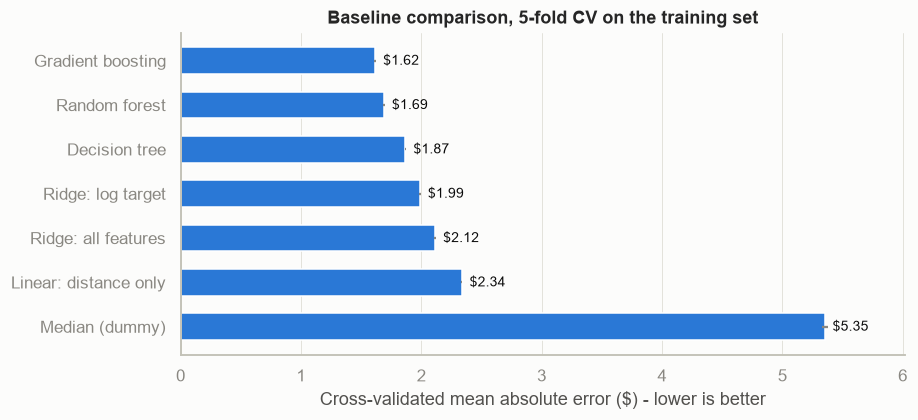

Knowing nothing:        MAE $5.35
Distance only:          MAE $2.34  (56% lower than the dummy)
Best (Gradient boosting): MAE $1.62  (31% lower than distance only)


In [34]:
ranked = cv_results.sort_values('CV MAE', ascending=False)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.barh(ranked.index, ranked['CV MAE'], xerr=ranked['MAE std'], color=BLUE, height=0.6, ecolor=MUTED)
for y_pos, value in enumerate(ranked['CV MAE']):
    ax.text(value, y_pos, f'  ${value:.2f}', va='center', color=INK, fontsize=9)
ax.set_xlabel('Cross-validated mean absolute error ($) - lower is better')
ax.set_title('Baseline comparison, 5-fold CV on the training set')
ax.grid(axis='y', visible=False)
ax.margins(x=0.12)
plt.show()

dummy_mae, meter_mae = cv_results.loc['Median (dummy)', 'CV MAE'], cv_results.loc['Linear: distance only', 'CV MAE']
best_baseline = cv_results['CV MAE'].idxmin()
best_mae = cv_results.loc[best_baseline, 'CV MAE']
print(f"Knowing nothing:        MAE ${dummy_mae:.2f}")
print(f"Distance only:          MAE ${meter_mae:.2f}  ({1 - meter_mae / dummy_mae:.0%} lower than the dummy)")
print(f"Best ({best_baseline}): MAE ${best_mae:.2f}  ({1 - best_mae / meter_mae:.0%} lower than distance only)")

**Result.**

* **The dummy sets the scale:** predicting the median for every trip gives an MAE of \$5.35.
* **Distance alone removes 56% of that error** (\$2.34). This is the quantitative answer to Q5.
* **The other features help a linear model a little:** Ridge on all features reaches \$2.12.
* **The log target trades RMSE for MAE:** it lowers the MAE to \$1.99 but raises the RMSE from 4.09 to 4.20, because it optimises relative error and gives up accuracy on the expensive trips.
* **Non-linear models are clearly better:** the decision tree reaches \$1.87, the random forest \$1.69 and gradient boosting \$1.62, which is 31% below the distance-only model.
* **The ranking is stable.** The MAE varies by at most \$0.007 between folds for every real model, while neighbouring models differ by \$0.07 or more.
* **The random forest is not worth its cost here.** It takes about three and a half times as long to fit as gradient boosting (13 s against 4 s) and is less accurate.

## 8. Tuning the gradient-boosting model

A randomised search over the main gradient-boosting settings, scored on MAE. To keep it to a few minutes the search runs 8 candidates × 3 folds on a subsample of the training set, with early stopping; the winning settings are then refitted on the **full** training set. (The original notebook's grid search took 40 fits of 11–22 minutes each.)

In [35]:
tune_idx = X_train.sample(min(TUNING_SAMPLE, len(X_train)), random_state=RANDOM_STATE).index
search = RandomizedSearchCV(
    make_model_pipeline(HistGradientBoostingRegressor(early_stopping=True, n_iter_no_change=20, random_state=RANDOM_STATE)),
    param_distributions={
        'model__learning_rate': [0.05, 0.1, 0.2],
        'model__max_iter': [200, 400],
        'model__max_leaf_nodes': [31, 63, 127],
        'model__min_samples_leaf': [20, 50, 100],
        'model__l2_regularization': [0.0, 0.1, 1.0],
    },
    n_iter=8, cv=3, scoring='neg_mean_absolute_error', random_state=RANDOM_STATE, refit=False)

start = time.time()
search.fit(X_train.loc[tune_idx], y_train.loc[tune_idx])
print(f"Search finished in {time.time() - start:.0f}s")

tuning = (pd.DataFrame(search.cv_results_)
            .assign(cv_mae=lambda t: -t['mean_test_score'])
            .sort_values('cv_mae')
            [['cv_mae', 'std_test_score', 'mean_fit_time'] + [c for c in search.cv_results_ if c.startswith('param_')]])
tuning.columns = [c.replace('param_model__', '') for c in tuning.columns]
display(tuning.round(3))

Search finished in 41s


,cv_mae,std_test_score,mean_fit_time,min_samples_leaf,max_leaf_nodes,max_iter,learning_rate,l2_regularization
2,1.601,0.016,2.072,100,63,200,0.10,1.0
0,1.617,0.017,1.242,100,63,400,0.20,1.0
5,1.623,0.010,1.570,100,31,400,0.10,0.0
4,1.625,0.020,1.073,50,63,200,0.20,0.1
6,1.637,0.016,1.026,100,31,400,0.20,0.1
7,1.643,0.022,1.389,20,127,400,0.20,0.0
3,1.645,0.018,1.789,50,31,200,0.05,0.1
1,1.645,0.019,1.786,50,31,200,0.05,1.0


In [36]:
tuned = make_model_pipeline(HistGradientBoostingRegressor(early_stopping=True, n_iter_no_change=20, random_state=RANDOM_STATE))
tuned.set_params(**search.best_params_)
tuned_scores = cross_validate(tuned, X_train, y_train, cv=cv, scoring=scoring)
cv_results.loc['Gradient boosting (tuned)'] = pd.Series({
    'CV MAE': -tuned_scores['test_MAE'].mean(), 'MAE std': tuned_scores['test_MAE'].std(),
    'CV RMSE': -tuned_scores['test_RMSE'].mean(), 'CV R2': tuned_scores['test_R2'].mean(),
    'fit time (s)': tuned_scores['fit_time'].mean()})
models['Gradient boosting (tuned)'] = tuned

FINAL_NAME = cv_results['CV MAE'].idxmin()
print("Best settings:", {k.replace('model__', ''): v for k, v in search.best_params_.items()})
print(f"Default gradient boosting CV MAE: {cv_results.loc['Gradient boosting', 'CV MAE']:.3f}")
print(f"Tuned gradient boosting CV MAE:   {cv_results.loc['Gradient boosting (tuned)', 'CV MAE']:.3f}")
print(f"Final model (lowest CV MAE on the full training set): {FINAL_NAME}")

Best settings: {'min_samples_leaf': 100, 'max_leaf_nodes': 63, 'max_iter': 200, 'learning_rate': 0.1, 'l2_regularization': 1.0}
Default gradient boosting CV MAE: 1.618
Tuned gradient boosting CV MAE:   1.534
Final model (lowest CV MAE on the full training set): Gradient boosting (tuned)


**Result.** Tuning lowered the cross-validated MAE on the full training set from \$1.618 to \$1.534 (5%), so the tuned model is the final model. Its settings are a learning rate of 0.1, 200 iterations, 63 leaves per tree, at least 100 trips per leaf and an L2 penalty of 1.0. The choice is made on the training set only; the test set has still not been touched.

Two caveats. The best two candidates in the search differ by \$0.016, which is about the spread between folds (0.010–0.022), so the order of the top few is not firm. And the winning values of `min_samples_leaf` and `l2_regularization` are the largest ones offered, so a wider grid could do slightly better.

## 9. Evaluation on the held-out test set

Every model is refitted on the full training set and scored once on the 20% it has never seen. Test scores close to the cross-validation scores mean the CV estimate was trustworthy and nothing leaked.

In [37]:
def regression_report(y_true, y_pred):
    error = np.asarray(y_pred) - np.asarray(y_true)
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'Median AE': median_absolute_error(y_true, y_pred),
            'R2': r2_score(y_true, y_pred),
            'within $2': (np.abs(error) <= 2).mean()}


fitted, predictions, rows = {}, {}, []
for name, pipeline in models.items():
    fitted[name] = clone(pipeline).fit(X_train, y_train)
    predictions[name] = fitted[name].predict(X_test)
    rows.append({'model': name, **regression_report(y_test, predictions[name])})

test_results = pd.DataFrame(rows).set_index('model')
test_results.insert(1, 'CV MAE', cv_results['CV MAE'])
display(test_results.sort_values('MAE').style.format({'MAE': '{:.3f}', 'CV MAE': '{:.3f}', 'RMSE': '{:.3f}', 'Median AE': '{:.3f}',
                                                      'R2': '{:.4f}', 'within $2': '{:.1%}'}))

final_model = fitted[FINAL_NAME]
y_pred = predictions[FINAL_NAME]
final_report = test_results.loc[FINAL_NAME]
print(f"Final model: {FINAL_NAME}")
print(f"Test MAE ${final_report['MAE']:.2f} (CV estimate ${final_report['CV MAE']:.2f}), RMSE ${final_report['RMSE']:.2f}, "
      f"R2 {final_report['R2']:.3f}; {final_report['within $2']:.0%} of trips predicted within $2.")
print(f"Mean test fare ${y_test.mean():.2f}, so MAE is {final_report['MAE'] / y_test.mean():.0%} of the average fare.")

,MAE,CV MAE,RMSE,Median AE,R2,within $2
model,,,,,,
Gradient boosting (tuned),1.538,1.534,3.308,0.881,0.8782,81.2%
Gradient boosting,1.621,1.618,3.394,0.959,0.8718,79.6%
Random forest,1.693,1.691,3.484,1.040,0.8649,77.8%
Decision tree,1.869,1.869,3.683,1.187,0.8490,73.7%
Ridge: log target,1.992,1.990,4.207,1.150,0.8030,72.8%
Ridge: all features,2.120,2.116,4.095,1.360,0.8133,67.0%
Linear: distance only,2.339,2.336,4.486,1.411,0.7760,65.1%
Median (dummy),5.347,5.352,9.886,3.000,-0.0878,37.8%


Final model: Gradient boosting (tuned)
Test MAE $1.54 (CV estimate $1.53), RMSE $3.31, R2 0.878; 81% of trips predicted within $2.
Mean test fare $11.31, so MAE is 14% of the average fare.


### 9.1 Predictions and residuals

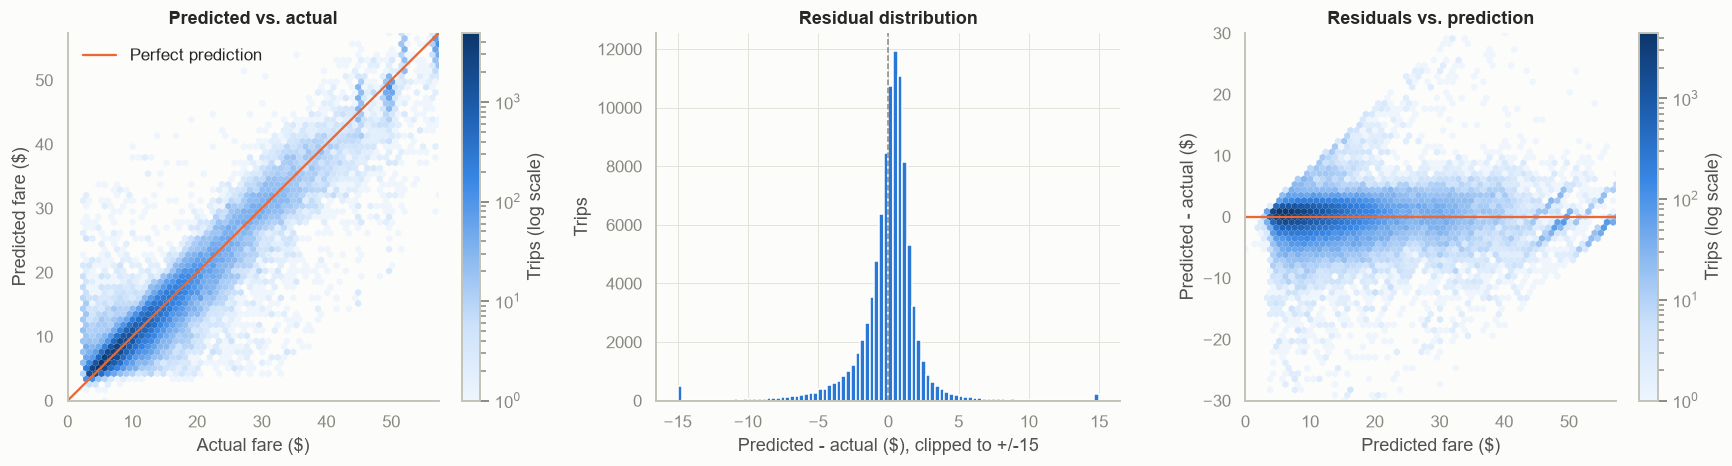

Mean residual (bias): -0.014   median: +0.319
Absolute error percentiles - 50%: 0.88, 90%: 3.07, 99%: 12.03


In [38]:
residual = y_pred - y_test.values
limit = np.quantile(y_test, 0.995)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
inside = (y_test.values <= limit) & (y_pred <= limit) & (np.abs(residual) <= 30)
hb = axes[0].hexbin(y_test.values[inside], y_pred[inside], gridsize=60, bins='log', cmap=SEQ, mincnt=1, extent=(0, limit, 0, limit), linewidths=0)
axes[0].plot([0, limit], [0, limit], color=ORANGE, lw=1.5, label='Perfect prediction')
axes[0].set_xlim(0, limit)
axes[0].set_ylim(0, limit)
axes[0].set_xlabel('Actual fare ($)')
axes[0].set_ylabel('Predicted fare ($)')
axes[0].set_title('Predicted vs. actual')
axes[0].legend(loc='upper left', frameon=False)
axes[0].grid(False)
fig.colorbar(hb, ax=axes[0], label='Trips (log scale)')

axes[1].hist(np.clip(residual, -15, 15), bins=90, color=BLUE)
axes[1].axvline(0, color=MUTED, ls='--', lw=1)
axes[1].set_xlabel('Predicted - actual ($), clipped to +/-15')
axes[1].set_ylabel('Trips')
axes[1].set_title('Residual distribution')

hb2 = axes[2].hexbin(y_pred[inside], residual[inside], gridsize=60, bins='log', cmap=SEQ, mincnt=1, extent=(0, limit, -30, 30), linewidths=0)
axes[2].axhline(0, color=ORANGE, lw=1.5)
axes[2].set_xlim(0, limit)
axes[2].set_ylim(-30, 30)
axes[2].set_xlabel('Predicted fare ($)')
axes[2].set_ylabel('Predicted - actual ($)')
axes[2].set_title('Residuals vs. prediction')
axes[2].grid(False)
fig.colorbar(hb2, ax=axes[2], label='Trips (log scale)')
plt.tight_layout()
plt.show()

print(f"Mean residual (bias): {residual.mean():+.3f}   median: {np.median(residual):+.3f}")
print(f"Absolute error percentiles - 50%: {np.percentile(np.abs(residual), 50):.2f}, "
      f"90%: {np.percentile(np.abs(residual), 90):.2f}, 99%: {np.percentile(np.abs(residual), 99):.2f}")

**Result.** Predictions follow the diagonal and the residuals form a narrow peak around zero. Half of the test trips are predicted within \$0.88, 90% within \$3.07 and 99% within \$12.03, so the average error is carried by a small number of trips the model cannot explain from pickup, dropoff and time alone. Waiting time and route are not in the data.

The mean residual is −\$0.01 but the median is +\$0.32: the model slightly over-predicts a typical trip and under-predicts the expensive tail. The residuals also fan out as the fare grows. The diagonal streaks at the right of the third panel are the flat fares, where the actual fare is one fixed value while the prediction varies.

### 9.2 Where is the model weak?

The same test errors, split by trip type. **MAE** is the size of the error; **bias** is its direction (positive = the model predicts too much).

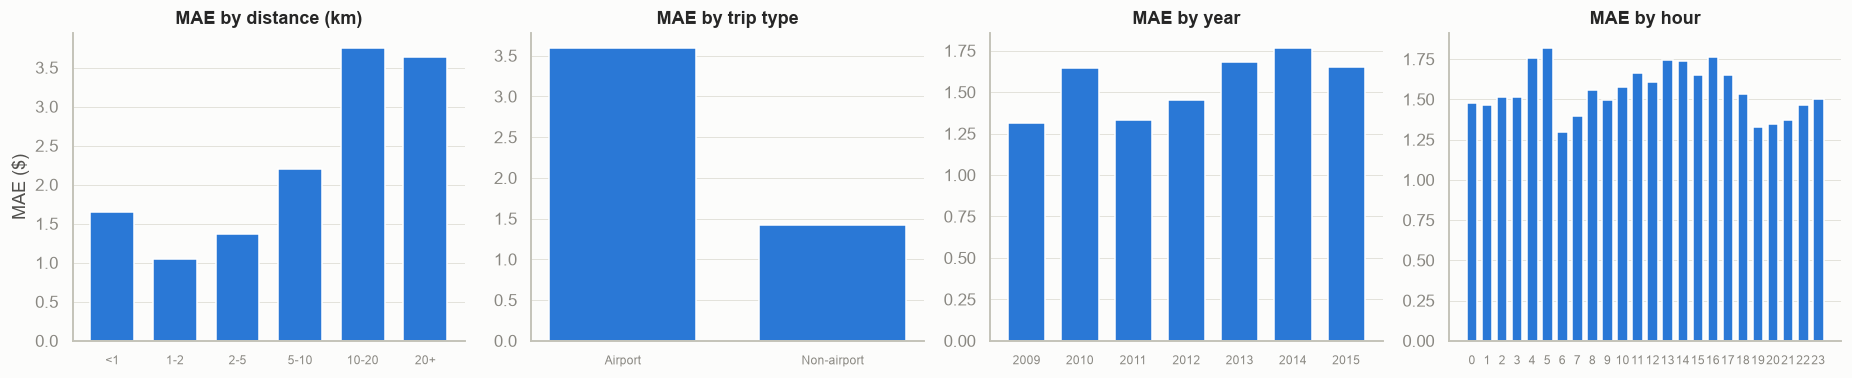

,trips,mean fare,MAE,bias,MAE % of mean fare
Distance (km),,,,,
<1,15221,5.63,1.65,-0.02,29.28
1-2,29084,6.90,1.04,0.00,15.13
2-5,35077,10.60,1.37,-0.00,12.90
5-10,12257,19.51,2.20,-0.06,11.27
10-20,3726,36.27,3.75,-0.10,10.35
20+,1100,53.14,3.63,0.14,6.84


,trips,mean fare,MAE,bias,MAE % of mean fare
Trip type,,,,,
Airport,5342,37.39,3.60,-0.05,9.62
Non-airport,91123,9.78,1.42,-0.01,14.49


,trips,mean fare,MAE,bias,MAE % of mean fare
Year,,,,,
2009,15095,9.86,1.31,-0.00,13.30
2010,14646,10.16,1.65,0.00,16.19
2011,15008,10.48,1.33,-0.00,12.72
2012,15487,11.07,1.45,-0.05,13.09
2013,14979,12.64,1.68,-0.04,13.32
2014,14471,12.99,1.77,-0.02,13.60
2015,6779,12.87,1.65,0.05,12.85


In [39]:
segments = add_trip_features(X_test)
segments['actual'] = y_test
segments['error'] = residual
segments['abs_error'] = np.abs(residual)
segments['Distance (km)'] = pd.cut(segments['trip_km'], [0, 1, 2, 5, 10, 20, np.inf], labels=['<1', '1-2', '2-5', '5-10', '10-20', '20+'])
segments['Trip type'] = np.where((segments['airport_pickup'] == 1) | (segments['airport_dropoff'] == 1), 'Airport', 'Non-airport')
segments['Year'] = segments['year'].astype(int)
segments['Hour'] = segments['hour'].astype(int)


def error_by(col):
    grouped = segments.groupby(col, observed=True)
    table = pd.DataFrame({'trips': grouped.size(), 'mean fare': grouped['actual'].mean(),
                          'MAE': grouped['abs_error'].mean(), 'bias': grouped['error'].mean()})
    table['MAE % of mean fare'] = 100 * table['MAE'] / table['mean fare']
    return table


fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col in zip(axes, ['Distance (km)', 'Trip type', 'Year', 'Hour']):
    table = error_by(col)
    ax.bar([str(i) for i in table.index], table['MAE'], color=BLUE, width=0.7)
    ax.set_title(f'MAE by {col.lower()}')
    ax.set_ylabel('MAE ($)' if ax is axes[0] else '')
    ax.grid(axis='x', visible=False)
    ax.tick_params(axis='x', labelsize=8)
plt.tight_layout()
plt.show()

for col in ['Distance (km)', 'Trip type', 'Year']:
    display(error_by(col).round(2))

**Result.**

* **Distance.** The dollar error rises with distance, from \$1.04 for 1–2 km to \$3.75 for 10–20 km, but only because the fares are larger: relative to the mean fare it *falls* from 15% to 7% for trips over 20 km.
* **Very short trips are the weakest segment.** Under 1 km the MAE is 29% of the mean fare. For these trips the straight-line distance says little about what the meter charged.
* **Airport trips** have an MAE of \$3.60 against \$1.42 for the rest, but that is 9.6% of their mean fare against 14.5%.
* **No systematic bias.** The bias stays within ±\$0.14 in every segment and does not trend across years, so the model has absorbed the 2012 fare change.
* **2010 stands out**, with an MAE of \$1.65 against \$1.31 in 2009 and \$1.33 in 2011. This notebook does not explain why.
* **Hour.** The error is highest at 4:00–5:00, the hours with the longest trips, and in the mid-afternoon; it is lowest at 6:00 and 19:00–20:00.

### 9.3 What does the model rely on?

**Permutation importance**: shuffle one column in the test data and measure how much the MAE gets worse. Unlike the impurity-based importances used in the original notebook, it is measured on unseen data and is not biased towards high-cardinality features.

* Left — shuffling each of the nine **raw inputs**. This is the clean answer to "which inputs matter", because each raw column feeds several engineered features.
* Right — shuffling each **engineered feature** on its own. Features that duplicate each other (`trip_km`, `log_trip_km`, `manhattan_km`) share their importance, so each looks smaller than the group really is.

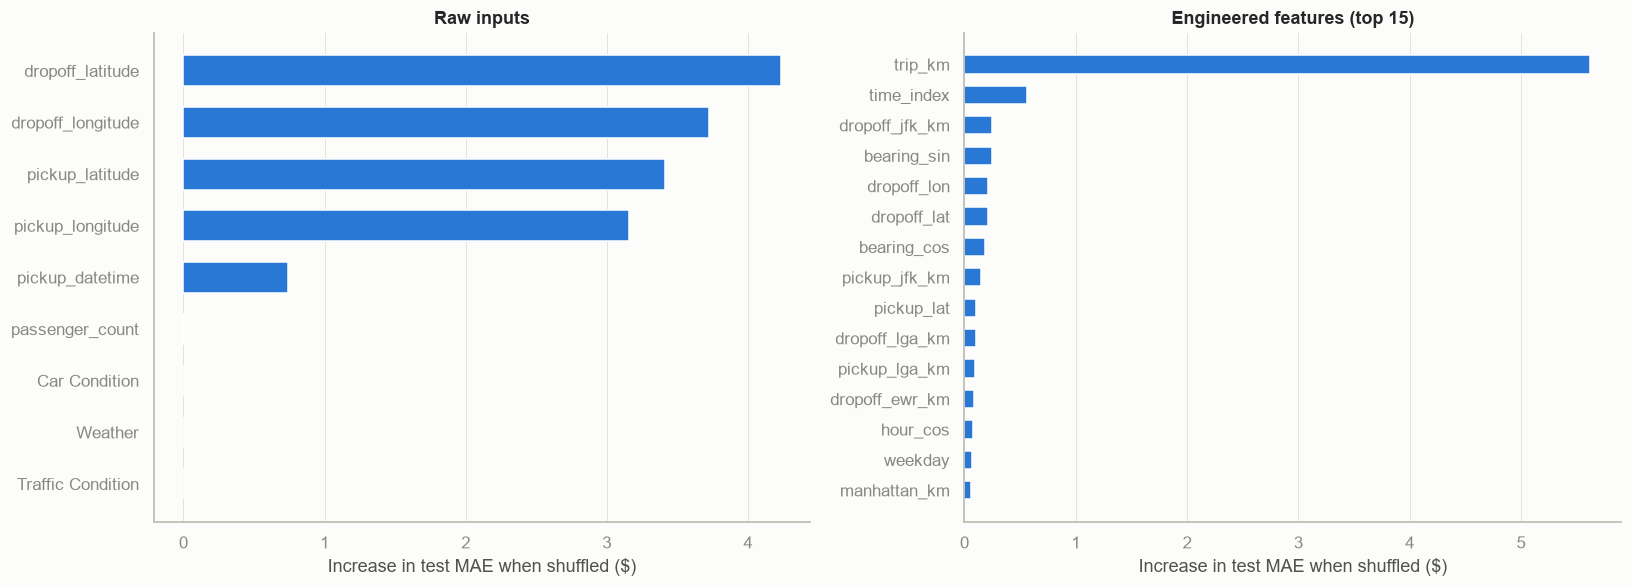

Importance of the three category columns (increase in MAE, $):
Car Condition        0.0001
Weather             -0.0001
Traffic Condition   -0.0003
Least useful engineered features: Traffic Condition_Flow Traffic, Traffic Condition_Congested Traffic, Weather_rainy, Weather_stormy, Weather_sunny, is_rush_hour


In [40]:
imp_idx = X_test.sample(min(IMPORTANCE_SAMPLE, len(X_test)), random_state=RANDOM_STATE).index
X_imp, y_imp = X_test.loc[imp_idx], y_test.loc[imp_idx]

raw_imp = permutation_importance(final_model, X_imp, y_imp, scoring='neg_mean_absolute_error', n_repeats=5, random_state=RANDOM_STATE)
raw_importance = pd.Series(raw_imp.importances_mean, index=X_imp.columns).sort_values()

feature_names = final_model.named_steps['prep'].get_feature_names_out()
engineered = final_model[:-1].transform(X_imp)
eng_imp = permutation_importance(final_model.named_steps['model'], engineered, y_imp, scoring='neg_mean_absolute_error',
                                 n_repeats=5, random_state=RANDOM_STATE)
eng_importance = pd.Series(eng_imp.importances_mean, index=feature_names).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(raw_importance.index, raw_importance.values, color=BLUE, height=0.6)
axes[0].set_title('Raw inputs')
axes[1].barh(eng_importance.index[-15:], eng_importance.values[-15:], color=BLUE, height=0.6)
axes[1].set_title('Engineered features (top 15)')
for ax in axes:
    ax.set_xlabel('Increase in test MAE when shuffled ($)')
    ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

category_importance = raw_importance[CAT_COLS]
print("Importance of the three category columns (increase in MAE, $):")
print(category_importance.round(4).to_string())
print(f"Least useful engineered features: {', '.join(eng_importance.index[:6])}")

**Result.** Shuffling `Car Condition`, `Weather` or `Traffic Condition` changes the test MAE by less than \$0.001, and `passenger_count` is also at zero. The model confirms the EDA (4.5): these four inputs could be dropped with no loss.

Each of the four coordinates costs \$3.2 to \$4.3 of MAE when shuffled. That is distance *and* location together, since shuffling one coordinate breaks both. `pickup_datetime` costs \$0.74. Among the engineered features `trip_km` dominates (about \$5.6), followed by `time_index` (about \$0.55), which carries the fare level of the period; everything else is below \$0.3. `log_trip_km` and `manhattan_km` look small only because they duplicate `trip_km`.

### 9.4 Would more data help?

A learning curve: the final model is retrained on growing subsets and scored on held-out folds. If the validation line is still falling at the right edge, more trips would help; if it has flattened, the limit is the features, not the amount of data. The gap between the two lines is the amount of overfitting.

**Result.** The validation MAE falls from \$1.783 with 10,000 trips to \$1.579 with 100,000, and the last step (75,000 → 100,000) still gains \$0.021. The curve is flattening but not flat, which agrees with the \$1.534 obtained in section 8 with about 309,000 trips per fold. The gap between training and validation is \$0.15, so overfitting is mild. More data would bring only small gains; a larger improvement has to come from new information such as route distance or duration.

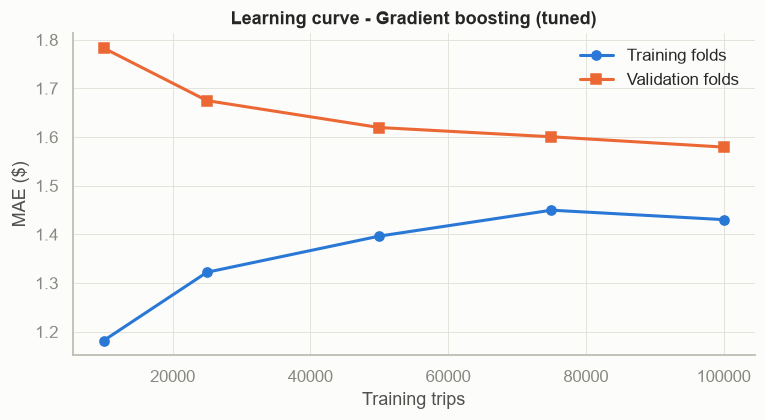

Validation MAE at 10,000 trips: 1.783; at 100,000 trips: 1.579
Gain from the last step (75,000 -> 100,000 trips): 0.021
Train/validation gap at full size: 0.149


In [41]:
curve_idx = X_train.sample(min(CURVE_SAMPLE, len(X_train)), random_state=RANDOM_STATE).index
sizes, train_scores, val_scores = learning_curve(
    clone(final_model), X_train.loc[curve_idx], y_train.loc[curve_idx], train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],
    cv=3, scoring='neg_mean_absolute_error', shuffle=True, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(sizes, -train_scores.mean(axis=1), marker='o', color=BLUE, lw=2, label='Training folds')
ax.plot(sizes, -val_scores.mean(axis=1), marker='s', color=ORANGE, lw=2, label='Validation folds')
ax.set_xlabel('Training trips')
ax.set_ylabel('MAE ($)')
ax.set_title(f'Learning curve - {FINAL_NAME}')
ax.legend(frameon=False)
plt.show()

validation_mae = -val_scores.mean(axis=1)
print(f"Validation MAE at {sizes[0]:,} trips: {validation_mae[0]:.3f}; at {sizes[-1]:,} trips: {validation_mae[-1]:.3f}")
print(f"Gain from the last step ({sizes[-2]:,} -> {sizes[-1]:,} trips): {validation_mae[-2] - validation_mae[-1]:.3f}")
print(f"Train/validation gap at full size: {validation_mae[-1] + train_scores.mean(axis=1)[-1]:.3f}")

## 10. Leakage check: why these scores differ from the original notebook

`Task-2.ipynb` reported a test **MAE of 0.178** and **R² of 0.947** for its tuned random forest. Its feature list included `fare_per_km`, defined as `fare_amount / distance`. With `distance` also in the features, the model only has to multiply the two columns to recover the fare exactly — it is being given the answer. In its own importance table, `fare_per_km` was the second most important feature.

That number cannot be reproduced in practice: to compute `fare_per_km` for a new trip you would already need to know its fare.

The experiment below makes the effect measurable. It takes this notebook's final model, adds that single column, and changes nothing else.

In [42]:
F_train, F_test = add_trip_features(X_train), add_trip_features(X_test)
F_train['fare_per_km'] = y_train / clean.loc[X_train.index, 'distance']
F_test['fare_per_km'] = y_test / clean.loc[X_test.index, 'distance']

leaky_model = Pipeline([('prep', make_preprocessor(NUM_FEATURES + ['fare_per_km'])),
                        ('model', clone(final_model.named_steps['model']))]).fit(F_train, y_train)
leaky_report = regression_report(y_test, leaky_model.predict(F_test))

leakage = pd.DataFrame({
    'Original notebook, as reported (random forest + fare_per_km)': {'MAE': 0.1781, 'RMSE': 2.2281, 'R2': 0.9474},
    f'This notebook: {FINAL_NAME} + fare_per_km (leaked)': leaky_report,
    f'This notebook: {FINAL_NAME} (honest)': final_report.to_dict(),
}).T[['MAE', 'RMSE', 'R2']]
display(leakage.round(4))
print(f"Adding the leaked column cuts test MAE from ${final_report['MAE']:.2f} to ${leaky_report['MAE']:.2f} "
      f"({final_report['MAE'] / leaky_report['MAE']:.0f}x lower) without the model knowing anything more about the trip.")

,MAE,RMSE,R2
"Original notebook, as reported (random forest + fare_per_km)",0.1781,2.2281,0.9474
This notebook: Gradient boosting (tuned) + fare_per_km (leaked),0.2420,1.5602,0.9729
This notebook: Gradient boosting (tuned) (honest),1.5378,3.3082,0.8782


Adding the leaked column cuts test MAE from $1.54 to $0.24 (6x lower) without the model knowing anything more about the trip.


**How to read the table.** The first two rows are both "too good": their MAE is a small fraction of the honest one because the answer is in the inputs. The last row is the error to expect on a trip whose fare is not yet known, and it is the only one of the three that describes a usable model. The original row is not directly comparable on RMSE and R², because that notebook also cleaned the data differently and clipped its features.

The general rule this illustrates: a feature is only legitimate if it could be computed **at prediction time, before the target exists**.

## 11. Save and reuse the pipeline

The whole pipeline — feature engineering, imputing, encoding and the model — is saved as **one file**. The original notebook saved the model and the scaler separately and left out the encoding, feature and selection steps, so its saved model could not score a raw trip.

To use the file elsewhere, keep `trip_features.py` next to it (the pipeline refers to the functions defined there).

In [43]:
MODEL_FILE = 'nyc_taxi_fare_pipeline.joblib'
joblib.dump(final_model, MODEL_FILE)

loaded = joblib.load(MODEL_FILE)
assert np.allclose(loaded.predict(X_test.head(100)), final_model.predict(X_test.head(100)))
print(f"Saved {MODEL_FILE}; the reloaded pipeline reproduces the original predictions.")

new_trips = pd.DataFrame([
    {'pickup_datetime': '2014-06-12 18:30:00', 'pickup': (40.7580, -73.9855), 'dropoff': (40.6413, -73.7781), 'label': 'Times Square -> JFK'},
    {'pickup_datetime': '2014-06-12 18:30:00', 'pickup': (40.7580, -73.9855), 'dropoff': (40.7527, -73.9772), 'label': 'Times Square -> Grand Central'},
])
raw_trips = pd.DataFrame({
    'pickup_datetime': new_trips['pickup_datetime'],
    'pickup_latitude': np.radians([p[0] for p in new_trips['pickup']]),
    'pickup_longitude': np.radians([p[1] for p in new_trips['pickup']]),
    'dropoff_latitude': np.radians([d[0] for d in new_trips['dropoff']]),
    'dropoff_longitude': np.radians([d[1] for d in new_trips['dropoff']]),
    'passenger_count': 1, 'Car Condition': 'Good', 'Weather': 'sunny', 'Traffic Condition': 'Flow Traffic',
})[RAW_FEATURES]
for label, predicted in zip(new_trips['label'], loaded.predict(raw_trips)):
    print(f"{label:<32} predicted fare ${predicted:.2f}")

Saved nyc_taxi_fare_pipeline.joblib; the reloaded pipeline reproduces the original predictions.
Times Square -> JFK              predicted fare $61.86
Times Square -> Grand Central    predicted fare $7.47


**Result.** The two hand-written trips are a sanity check that needs no test set.

* **Times Square → Grand Central: \$7.47.** A ride of under 1 km across Midtown should cost a few dollars, so this is plausible.
* **Times Square → JFK: \$61.86.** This is too high. The flat fare was \$52 in 2014, and the most common fare in the data after the 2012 change is \$57.3, the flat fare plus a toll (4.1). The prediction is therefore \$5–10 above the fare this trip would really have had, more than the average airport error of \$3.60 (9.2).

The model has learned that a JFK trip is expensive but not that it is *capped*. An explicit Manhattan ↔ JFK flat-fare flag is the most direct way to fix this.

## Summary

In [44]:
print(f"Data: {len(df):,} trips loaded, {len(clean):,} kept after validity rules ({len(clean) / len(df):.1%}).")
print(f"Split: {len(X_train):,} train / {len(X_test):,} test; {len(NUM_FEATURES) + len(CAT_FEATURES)} features from {len(RAW_FEATURES)} raw columns.\n")
display(test_results.sort_values('MAE')[['CV MAE', 'MAE', 'RMSE', 'R2']].round(3))
print(f"Final model: {FINAL_NAME}")
print(f"  test MAE ${final_report['MAE']:.2f} = {final_report['MAE'] / y_test.mean():.0%} of the average fare; "
      f"R2 {final_report['R2']:.3f}; {final_report['within $2']:.0%} of trips within $2")
print(f"  vs. predicting the median:  MAE ${test_results.loc['Median (dummy)', 'MAE']:.2f}")
print(f"  vs. distance only:          MAE ${test_results.loc['Linear: distance only', 'MAE']:.2f}")
print(f"  with the leaked feature:    MAE ${leaky_report['MAE']:.2f} (not achievable in practice)")
print(f"Most important raw inputs: {', '.join(raw_importance.index[::-1][:4])}")

Data: 500,000 trips loaded, 482,321 kept after validity rules (96.5%).
Split: 385,856 train / 96,465 test; 31 features from 9 raw columns.



,CV MAE,MAE,RMSE,R2
model,,,,
Gradient boosting (tuned),1.534,1.538,3.308,0.878
Gradient boosting,1.618,1.621,3.394,0.872
Random forest,1.691,1.693,3.484,0.865
Decision tree,1.869,1.869,3.683,0.849
Ridge: log target,1.990,1.992,4.207,0.803
Ridge: all features,2.116,2.120,4.095,0.813
Linear: distance only,2.336,2.339,4.486,0.776
Median (dummy),5.352,5.347,9.886,-0.088


Final model: Gradient boosting (tuned)
  test MAE $1.54 = 14% of the average fare; R2 0.878; 81% of trips within $2
  vs. predicting the median:  MAE $5.35
  vs. distance only:          MAE $2.34
  with the leaked feature:    MAE $0.24 (not achievable in practice)
Most important raw inputs: dropoff_latitude, dropoff_longitude, pickup_latitude, pickup_longitude


### What changed from the original notebook

| | Original | This version |
|---|---|---|
| Target leakage | `fare_per_km` used as a feature | Removed; effect measured in section 10 |
| Fitting preprocessing | On all rows, before the split | Inside the pipeline, on training folds only |
| Category columns | One-hot encoded, then silently dropped by a numeric-only filter | Encoded in the pipeline and reach every model |
| Models | One random forest | Seven baselines plus a tuned model, same CV |
| Tuning cost | 40 fits of 11–22 minutes | 24 short fits on a subsample |
| Feature importance | Impurity-based, on training data | Permutation, on test data |
| Saved artefact | Model + scaler | One pipeline that scores raw trips |
| "No influence" answers | Compared medians by eye | Backed by an effect size |

### Limitations

* **Random split.** Train and test mix all years. That measures how well the model fills in trips from the same period; predicting a *future* year would be harder, because fare schedules change (section 4.4).
* **One cleaning rule uses the target** (fare above \$100 for under 1 km). It removes a handful of rows from both train and test, so the reported error excludes those trips.
* **Straight-line distance.** The data has no route distance, duration or tolls — the things a meter actually charges for. The remaining error (section 9.1) is largely that missing information.
* **Time zone.** The night and rush-hour flags assume the timestamps are New York local time. The demand profile supports this (quietest at 5:00, busiest at 19:00), but the file does not state it.
* **Flat fares are not captured exactly.** The Times Square → JFK check in section 11 comes out \$5–10 too high; there is no explicit flat-fare feature.
* **Tuning was limited.** The search used a 120,000-trip subsample and its best settings sit at the edge of the grid (section 8).
* **`Car Condition`, `Weather`, `Traffic Condition`** behave like randomly assigned labels; conclusions about them describe this dataset, not real taxi pricing.

## 12. Task 3 — model selection and deployment files

This section covers Parts A and B of Task 3 (*Model Deployment*). The Flask app in `app.py` (Parts C and D) loads the files saved here.

### 12.1 Part A — model comparison

All eight models were already trained on the full training set and scored once on the held-out test set in section 9. The table below puts the three required test metrics next to three things that matter for deployment:

| Column | Meaning |
|---|---|
| **MAE, RMSE, R2** | Test-set metrics (96,465 trips the models never saw) |
| **Train MAE** | The same error on the training set; a large gap to the test MAE means overfitting |
| **ms per 1,000 trips / ms for 1 trip** | Prediction time for the whole pipeline, raw trip in, fare out |
| **file size (MB)** | Size of the saved pipeline |

In [45]:
speed_batch, one_trip = X_test.sample(1000, random_state=RANDOM_STATE), X_test.head(1)


def timed_ms(predict, repeats):
    start = time.perf_counter()
    for _ in range(repeats):
        predict()
    return 1000 * (time.perf_counter() - start) / repeats


rows = []
for name, model in fitted.items():
    joblib.dump(model, '_size_check.pkl', compress=3)
    rows.append({'model': name,
                 'Train MAE': mean_absolute_error(y_train, model.predict(X_train)),
                 'ms per 1,000 trips': timed_ms(lambda: model.predict(speed_batch), 5),
                 'ms for 1 trip': timed_ms(lambda: model.predict(one_trip), 20),
                 'file size (MB)': os.path.getsize('_size_check.pkl') / 1e6})
os.remove('_size_check.pkl')

comparison = test_results[['MAE', 'RMSE', 'R2']].join(pd.DataFrame(rows).set_index('model')).sort_values('MAE')
comparison.insert(1, 'Train MAE', comparison.pop('Train MAE'))
display(comparison.round(3))

best, runner_up = comparison.index[0], comparison.index[1]
print(f"Lowest test MAE: {best} (${comparison.loc[best, 'MAE']:.2f}); next: {runner_up} (${comparison.loc[runner_up, 'MAE']:.2f})")
print(f"Train/test MAE gap of {best}: ${comparison.loc[best, 'MAE'] - comparison.loc[best, 'Train MAE']:.2f}")

,MAE,Train MAE,RMSE,R2,"ms per 1,000 trips",ms for 1 trip,file size (MB)
model,,,,,,,
Gradient boosting (tuned),1.538,1.466,3.308,0.878,35.166,30.439,0.708
Gradient boosting,1.621,1.586,3.394,0.872,34.728,29.663,0.202
Random forest,1.693,1.614,3.484,0.865,54.885,37.786,10.004
Decision tree,1.869,1.820,3.683,0.849,22.753,20.645,0.029
Ridge: log target,1.992,1.989,4.207,0.803,23.961,21.728,0.003
Ridge: all features,2.120,2.115,4.095,0.813,23.255,20.987,0.003
Linear: distance only,2.339,2.336,4.486,0.776,20.794,19.191,0.002
Median (dummy),5.347,5.352,9.886,-0.088,25.533,20.830,0.002


Lowest test MAE: Gradient boosting (tuned) ($1.54); next: Gradient boosting ($1.62)
Train/test MAE gap of Gradient boosting (tuned): $0.07


**Which model is deployed, and why.** The deployed model is the **tuned gradient boosting** model. It has the best test-set result on all three metrics: an MAE of \$1.54, an RMSE of \$3.31 and an R² of 0.878, against \$1.62 / \$3.39 / 0.872 for the default gradient boosting and \$1.69 / \$3.48 / 0.865 for the random forest. Its training MAE (\$1.47) is only \$0.07 below its test MAE and its cross-validated estimate (\$1.53) agrees with the test score, so the advantage does not come from overfitting. Speed does not separate the models: every pipeline answers a single trip in roughly 20–40 ms, most of which is the shared feature step, and the chosen model is a 0.7 MB file where the random forest is 10 MB. The linear models are easier to explain, but they are \$0.45–0.80 worse per trip (MAE \$1.99–2.34), which is too large a gap to give up for interpretability; the permutation importance in section 9.3 is used to explain the chosen model instead.

### 12.2 Part B — save the model and its preprocessing

The chosen model is saved as **one file**, `uber_fare_model.pkl`. It is the whole scikit-learn pipeline, already fitted on the full training set in section 9:

1. `add_trip_features` — feature engineering from the nine raw trip columns;
2. the median imputer and the one-hot encoder;
3. the gradient-boosting model.

There is no separate scaler file. Tree-based models do not need scaling, and the preprocessing steps that are used live inside the pipeline, so a raw trip cannot reach the model without passing through them.

A second file, `uber_fare_metadata.json`, records what the app needs to check user input: the valid coordinate box, the passenger range and the category levels. These are the same limits as the cleaning rules in section 2.3, so the app accepts exactly the kind of trip the model was trained on.

The pipeline refers to the functions in `trip_features.py`, so that file has to stay next to the model.

In [46]:
MODEL_PATH, META_PATH = 'uber_fare_model.pkl', 'uber_fare_metadata.json'

deployed = fitted[FINAL_NAME]
joblib.dump(deployed, MODEL_PATH, compress=3)

lat_min, lat_max, lon_min, lon_max = NYC_BOX
metadata = {
    'model_name': FINAL_NAME,
    'trained_on_rows': len(X_train),
    'sklearn_version': sklearn.__version__,
    'raw_features': RAW_FEATURES,
    'coordinate_unit': 'radians',
    'limits': {'lat_min': lat_min, 'lat_max': lat_max, 'lon_min': lon_min, 'lon_max': lon_max,
               'passenger_min': 1, 'passenger_max': 6},
    'categories': {col: sorted(str(level) for level in X_train[col].unique()) for col in CAT_FEATURES},
    'training_period': [str(clean['pickup_datetime'].min()), str(clean['pickup_datetime'].max())],
    'test_metrics': {metric: float(final_report[metric]) for metric in ['MAE', 'RMSE', 'R2']},
}
with open(META_PATH, 'w') as f:
    json.dump(metadata, f, indent=2)

reloaded = joblib.load(MODEL_PATH)
assert np.allclose(reloaded.predict(X_test.head(100)), deployed.predict(X_test.head(100)))
print(f"Saved {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.2f} MB) and {META_PATH}.")
print(f"Model: {FINAL_NAME}, trained on {len(X_train):,} trips with scikit-learn {sklearn.__version__}.")
print("The reloaded pipeline reproduces the original predictions.")
print("Steps inside the saved pipeline:", [step for step, _ in reloaded.steps])

Saved uber_fare_model.pkl (0.71 MB) and uber_fare_metadata.json.
Model: Gradient boosting (tuned), trained on 385,856 trips with scikit-learn 1.9.1.
The reloaded pipeline reproduces the original predictions.
Steps inside the saved pipeline: ['features', 'prep', 'model']


### 12.3 Parts C and D — the Flask app

`app.py` loads `uber_fare_model.pkl` and `uber_fare_metadata.json` once at start-up. For every submitted form it checks the input against the limits above, converts the coordinates from degrees to radians (the unit of the dataset) and calls `predict` on the saved pipeline, so user input goes through the same steps, in the same order, as the training data.

`README.md` explains how to run the app and lists the test trips. The first two are the trips from section 11, so the fares shown in the browser can be checked against that cell.